# v2: new captchas (red letters on gray speckle)

The captcha changed: same 150x45 size, 5 characters and font, but red letters on gray speckle instead of black
letters crossed by gray lines. Keeping only the red pixels (`prep.ink`) removes nearly all the noise.

1. **Gold**: 200 random captchas, pre-labeled by v1's model; you check them (section 4). Test set only, never trained on.
2. **Relabel**: v1's model (`../models/captcha_cnn_ft_650.pt`) reads every captcha; where Apple Vision reads the same,
   that label is trusted (**agree** = training set). Disagreements go to your review queue.
3. **Train** a baseline on agree + your reviews, starting from v1's weights. **Test** on gold.
4. **Review** 50 at a time (disagreements first), **fine-tune**, repeat 4 until gold stops improving.

Before section 5: `python3 scripts/label_vision.py` from the project root (Vision reads of all captchas, ~12 min).

## 1. Setup and paths

In [1]:
import csv, json, math, os, random, sys, time
from collections import Counter
from concurrent.futures import ThreadPoolExecutor

import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
from PIL import Image
import matplotlib.pyplot as plt
from tqdm.auto import tqdm

sys.path.insert(0, "../scripts")
import prep   # ink(): red-letter mask, Vision helpers; shared with scripts/label_vision.py

# images: ../data/captchas.zip (100,000 captchas), read with prep.open_captcha(id); no loose PNGs
GOLD_CSV = "../data/gold.csv"                # 200 test captchas, never trained on or reviewed (audit_gold.py)
REVIEWS = "../data/reviews.json"             # your typed answers (review.py adds to it)
VISION_LABELS = "../data/labels_vision.csv"  # Apple Vision's read of every captcha (scripts/label_vision.py)
TEACHER = "../models/captcha_cnn_ft_650.pt"  # v1's best (old-style gold 93.42%): pre-labels gold, relabels all
LABELS_CSV = "../data/labels.csv"            # written by the relabel cell
CACHE = "../cache/ink_images.npz"            # cleaned images, so re-runs skip reading 100k PNGs
MODEL_PATH = "../models/captcha_cnn_v2.pt"   # the new baseline
FT_PATH = "../models/captcha_cnn_v2_ft.pt"   # the new baseline fine-tuned on your reviews
os.makedirs("../models", exist_ok=True)
os.makedirs("../cache", exist_ok=True)

SEED = 0
DEVICE = torch.device("mps" if torch.backends.mps.is_available() else "cpu")
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)

_teacher = torch.load(TEACHER, map_location="cpu")
ALPHABET, LENGTH = _teacher["alphabet"], _teacher["length"]   # same classes as v1 and the extension
assert (ALPHABET, LENGTH) == (prep.ALPHABET, prep.LENGTH)
CHAR_TO_IDX = {c: i for i, c in enumerate(ALPHABET)}
print("device:", DEVICE, "| alphabet:", ALPHABET)

device: mps | alphabet: 2345689ABDEFGHJLMNQRTYabdefghijmnqrty


/Users/varunmatta/miniconda3/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## 2. Load all images (red letters only, cached after the first run, ~1–2 min), Vision reads and gold

In [2]:
ALL_IDS = np.array(prep.captcha_ids())

cached = np.load(CACHE) if os.path.exists(CACHE) else None
if cached is not None and np.array_equal(cached["ids"], ALL_IDS):
    imgs = cached["imgs"]
else:
    t = time.time()
    with ThreadPoolExecutor(8) as ex:
        imgs = np.stack(list(ex.map(lambda i: prep.ink(prep.open_captcha(i)), ALL_IDS)))
    np.savez(CACHE, ids=ALL_IDS, imgs=imgs)
    print(f"read {len(imgs)} images in {time.time() - t:.0f}s")
H, W = imgs.shape[1:]
X = torch.from_numpy(imgs).to(DEVICE)   # uint8, all images on the GPU (~0.7 GB)
row_of = {i: k for k, i in enumerate(ALL_IDS)}

VISION = {}   # id -> Vision's read, "" where it gave no valid 5-character answer
if os.path.exists(VISION_LABELS):
    with open(VISION_LABELS) as f:
        VISION = {r["id"]: r["vision"] for r in csv.DictReader(f)}
GOLD = {}     # id -> {label, model, vision, checked}; filled by audit_gold.py
if os.path.exists(GOLD_CSV):
    with open(GOLD_CSV) as f:
        GOLD = {r["id"]: r for r in csv.DictReader(f)}
print("images:", imgs.shape, f"| Vision reads: {len(VISION)}/{len(ALL_IDS)}",
      f"| gold: {len(GOLD)} ({sum(bool(g['checked']) for g in GOLD.values())} checked)")

images: (100000, 45, 150) | Vision reads: 50850/100000 | gold: 200 (0 checked)


## 3. Model definition and helpers (same network as v1)

In [7]:
class CaptchaCNN(nn.Module):
    def __init__(self, n_classes, length=LENGTH, widths=(32, 64, 128, 192), dropout=0.3):
        super().__init__()
        layers, c_in = [], 1
        for c in widths:   # each block halves H and W: 45x150 -> 2x9
            layers += [
                nn.Conv2d(c_in, c, 3, padding=1, bias=False), nn.BatchNorm2d(c), nn.ReLU(inplace=True),
                nn.Conv2d(c, c, 3, padding=1, bias=False), nn.BatchNorm2d(c), nn.ReLU(inplace=True),
                nn.MaxPool2d(2),
            ]
            c_in = c
        self.features = nn.Sequential(*layers)
        n_cols = W // 2 ** len(widths)   # 9 columns left, kept apart so heads know left from right
        self.shared = nn.Sequential(nn.Flatten(), nn.Dropout(dropout),
                                    nn.Linear(c_in * n_cols, 512), nn.ReLU(inplace=True), nn.Dropout(dropout))
        self.heads = nn.ModuleList(nn.Linear(512, n_classes) for _ in range(length))

    def forward(self, x):
        z = self.features(x).mean(dim=2)   # average over height -> (B, C, columns)
        z = self.shared(z)
        return torch.stack([head(z) for head in self.heads], dim=1)   # (B, LENGTH, n_classes)

def to_input(x):
    """uint8 (B, H, W) -> float (B, 1, H, W) with ink = 1, paper = 0."""
    return (1 - x.float() / 255).unsqueeze(1)

def load_model(path):
    ckpt = torch.load(path, map_location=DEVICE)
    m = CaptchaCNN(len(ckpt["alphabet"]), ckpt["length"], ckpt["widths"], ckpt["config"]["dropout"]).to(DEVICE)
    m.load_state_dict(ckpt["state_dict"])
    return m.eval(), ckpt

@torch.no_grad()
def model_reads(m, ids, batch_size=2048, desc="model reads"):
    """Model reads + weakest-character confidence for a list of image ids."""
    m.eval()
    reads, confs = [], []
    for k in tqdm(range(0, len(ids), batch_size), desc=desc, leave=False):
        x = to_input(X[torch.tensor([row_of[i] for i in ids[k:k + batch_size]]).to(DEVICE)])
        conf, idx = m(x).softmax(-1).max(-1)
        reads += ["".join(ALPHABET[j] for j in p) for p in idx.cpu().tolist()]
        confs += conf.min(-1).values.cpu().tolist()
    return reads, confs

print(f"{sum(p.numel() for p in CaptchaCNN(len(ALPHABET)).parameters()) / 1e6:.2f}M parameters")

def show(i):
    """The original captcha, big enough to read (reviews and gold checks)."""
    plt.figure(figsize=(7, 2.1))
    plt.imshow(prep.open_captcha(i).convert("RGB"))
    plt.axis("off")
    plt.show()

1.82M parameters


## 4. Gold: build + pre-label 200 test captchas (first run), then check them
Enter = label right, type the truth if not, s = skip, q = stop. Re-run any time to continue; `q` right away just builds.
Gold scores stay provisional until all 200 are checked (pre-labels come from the teacher, so they flatter it).

0/200 gold checked, 200 to go


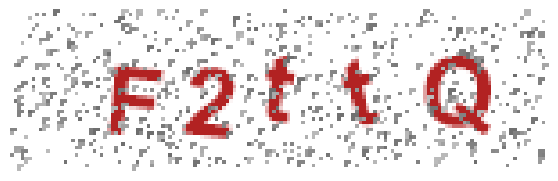

[1/200] 1841  label: F2ttQ  (Vision: F2ffQ)  Enter=right / type truth / s=skip / q=quit:  F2ttQ


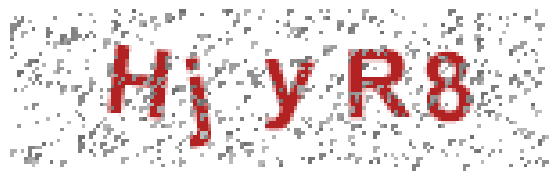

[2/200] 4322  label: HiyR5  (Vision: HjyR5)  Enter=right / type truth / s=skip / q=quit:  HjyR8


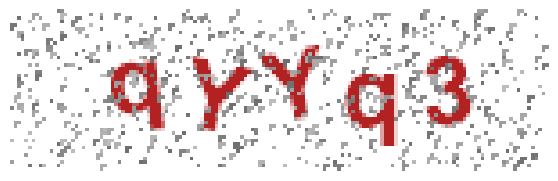

[3/200] 5929  label: qYYq3  (Vision: ayYq3)  Enter=right / type truth / s=skip / q=quit:  qYYq3


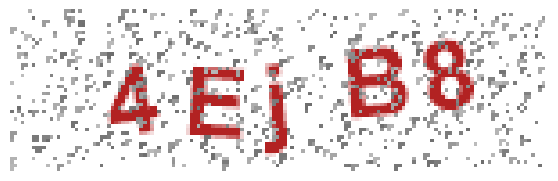

[4/200] 11956  label: 4EjB8  (Vision: 4EJB8)  Enter=right / type truth / s=skip / q=quit:  


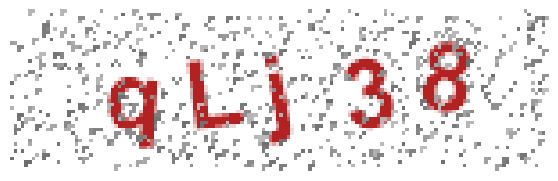

[5/200] 11998  label: qLj38  (Vision: QLJ38)  Enter=right / type truth / s=skip / q=quit:  


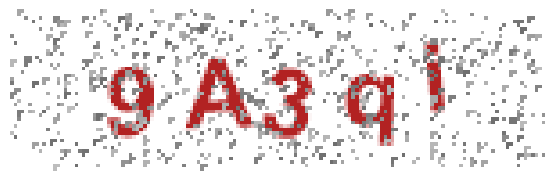

[6/200] 12226  label: 9A3qi  (Vision: 9A3qf)  Enter=right / type truth / s=skip / q=quit:  


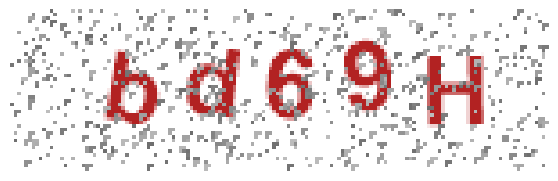

[7/200] 13304  label: bd69H  (Vision: -)  Enter=right / type truth / s=skip / q=quit:  


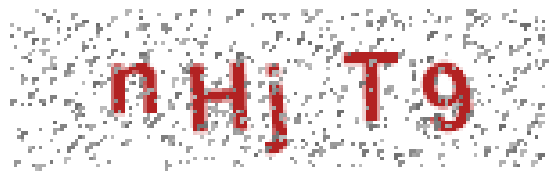

[8/200] 14295  label: nHiT9  (Vision: -)  Enter=right / type truth / s=skip / q=quit:  nHjT9


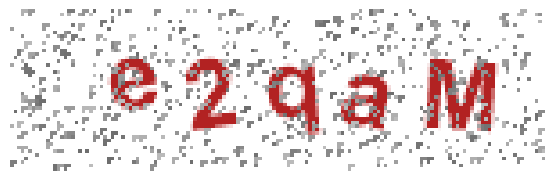

[9/200] 15689  label: a2qaM  (Vision: e2qaM)  Enter=right / type truth / s=skip / q=quit:  e2qaM


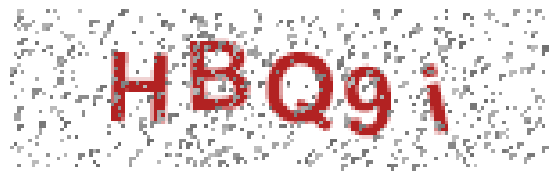

[10/200] 16312  label: HBQ9i  (Vision: HBQgf)  Enter=right / type truth / s=skip / q=quit:  


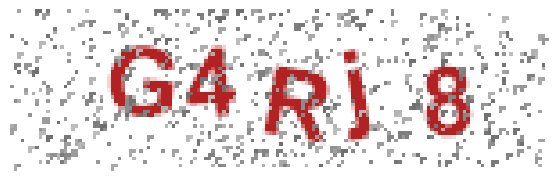

[11/200] 16360  label: G4Ri8  (Vision: -)  Enter=right / type truth / s=skip / q=quit:  G4Rj8


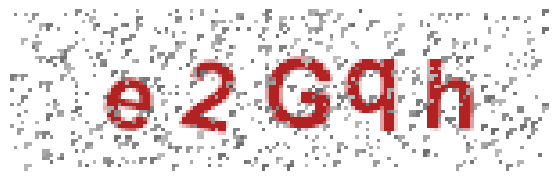

[12/200] 18678  label: e2Gqh  (Vision: e2G9h)  Enter=right / type truth / s=skip / q=quit:  e2Gqh


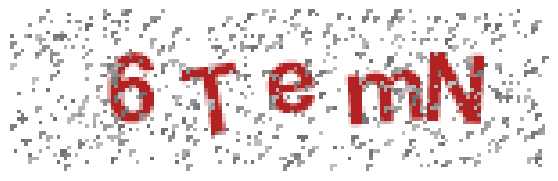

[13/200] 19184  label: 5TemN  (Vision: 6TEmN)  Enter=right / type truth / s=skip / q=quit:  6TemN


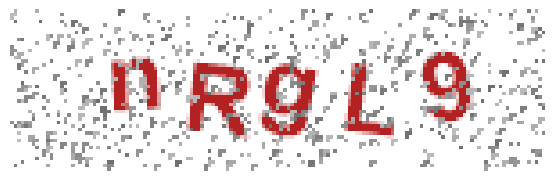

[14/200] 19263  label: nRgL9  (Vision: NRgL9)  Enter=right / type truth / s=skip / q=quit:  nRgL9


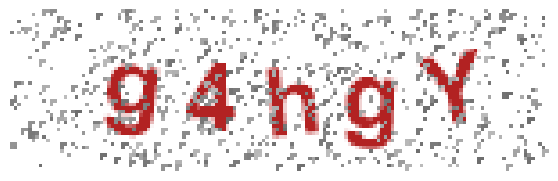

[15/200] 19602  label: g4hgY  (Vision: 94hgY)  Enter=right / type truth / s=skip / q=quit:  


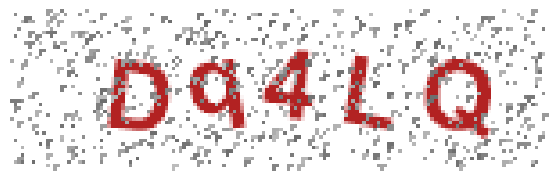

[16/200] 25506  label: Dq4LQ  (Vision: D94LQ)  Enter=right / type truth / s=skip / q=quit:  


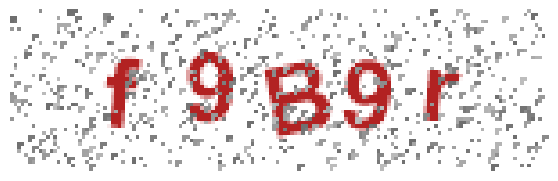

[17/200] 28676  label: f9B9r  (Vision: f989r)  Enter=right / type truth / s=skip / q=quit:  


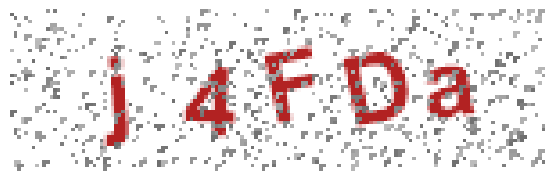

[18/200] 30868  label: j4FDa  (Vision: i4FDa)  Enter=right / type truth / s=skip / q=quit:  


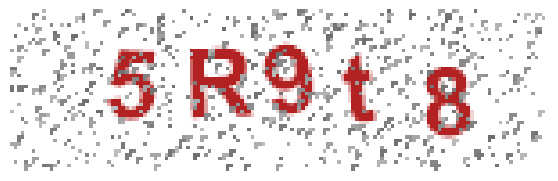

[19/200] 31734  label: 5R9t8  (Vision: -)  Enter=right / type truth / s=skip / q=quit:  


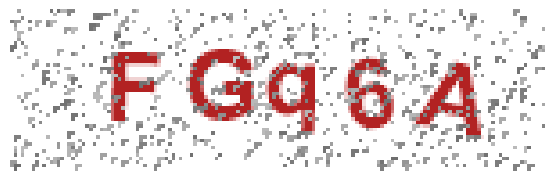

[20/200] 36073  label: FGq5A  (Vision: FG954)  Enter=right / type truth / s=skip / q=quit:  FGq6A


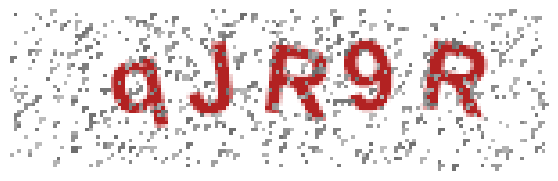

[21/200] 38055  label: qJR9R  (Vision: QJR9R)  Enter=right / type truth / s=skip / q=quit:  qJR9R


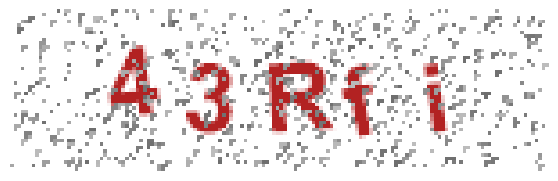

[22/200] 42626  label: 43Rii  (Vision: 43Rff)  Enter=right / type truth / s=skip / q=quit:  43Rfi


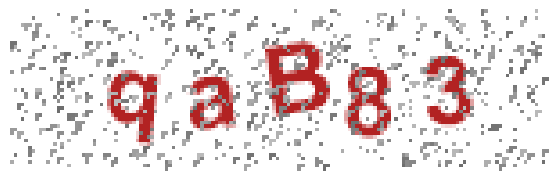

[23/200] 43587  label: qaB83  (Vision: qaBg3)  Enter=right / type truth / s=skip / q=quit:  qaB83


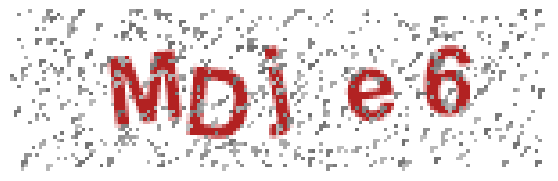

[24/200] 43615  label: MDie6  (Vision: MDje6)  Enter=right / type truth / s=skip / q=quit:  MDje6


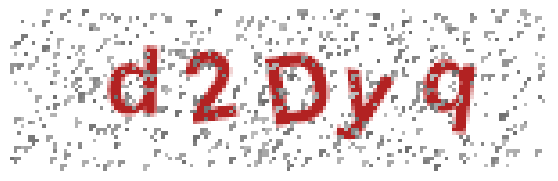

[25/200] 46841  label: d2Dyq  (Vision: d2Dyg)  Enter=right / type truth / s=skip / q=quit:  d2Dyq


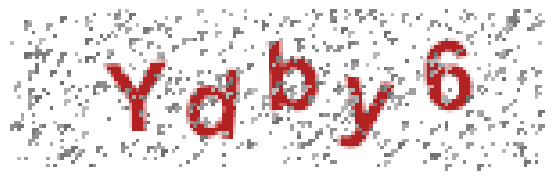

[26/200] 48515  label: Ydby6  (Vision: -)  Enter=right / type truth / s=skip / q=quit:  Ydby6


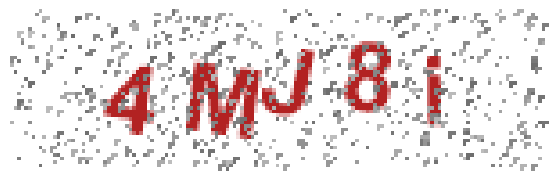

[27/200] 51288  label: 4MJ8i  (Vision: 4MJ8f)  Enter=right / type truth / s=skip / q=quit:  4MJ8i


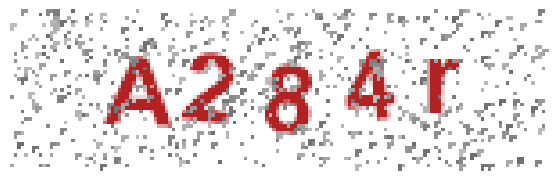

[28/200] 54975  label: A284r  (Vision: -)  Enter=right / type truth / s=skip / q=quit:  


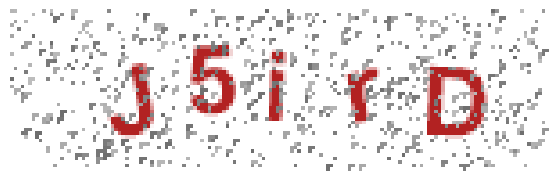

[29/200] 55787  label: J5iiD  (Vision: J5iTD)  Enter=right / type truth / s=skip / q=quit:  J5irD


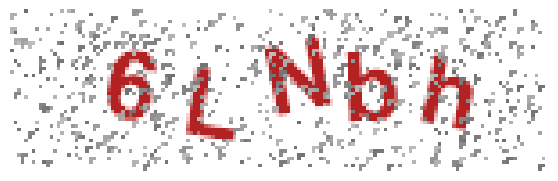

[30/200] 56908  label: 6LNbh  (Vision: 6fNbh)  Enter=right / type truth / s=skip / q=quit:  


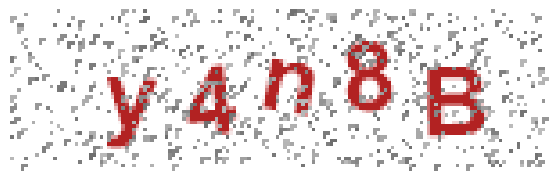

[31/200] 58025  label: y4n8B  (Vision: -)  Enter=right / type truth / s=skip / q=quit:  


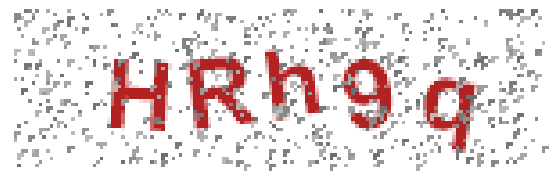

[32/200] 62460  label: HRh9q  (Vision: HRh99)  Enter=right / type truth / s=skip / q=quit:  


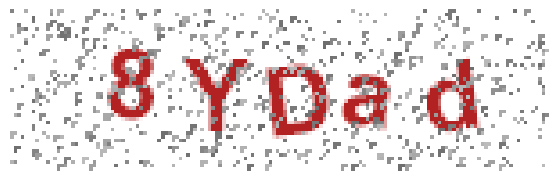

[33/200] 62469  label: 8YDad  (Vision: 5YDad)  Enter=right / type truth / s=skip / q=quit:  


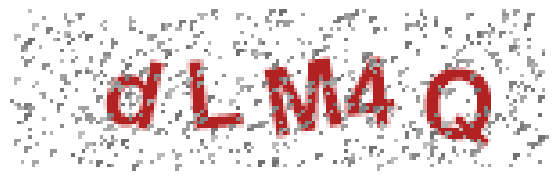

[34/200] 62523  label: dLM4Q  (Vision: dLMAQ)  Enter=right / type truth / s=skip / q=quit:  


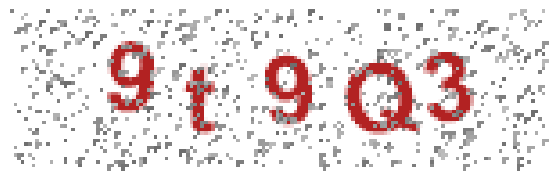

[35/200] 63760  label: 9t9Q3  (Vision: 9i9Q3)  Enter=right / type truth / s=skip / q=quit:  


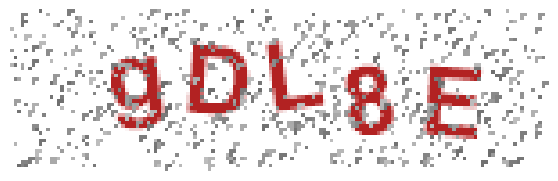

[36/200] 66577  label: gDLgE  (Vision: -)  Enter=right / type truth / s=skip / q=quit:  gDL8E


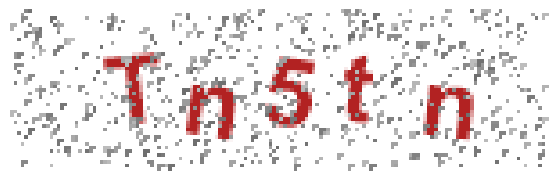

[37/200] 68393  label: Tn5tn  (Vision: -)  Enter=right / type truth / s=skip / q=quit:  


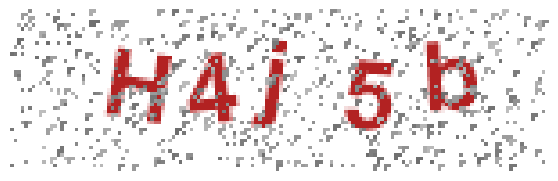

[38/200] 70817  label: HAj5b  (Vision: H4j5b)  Enter=right / type truth / s=skip / q=quit:  


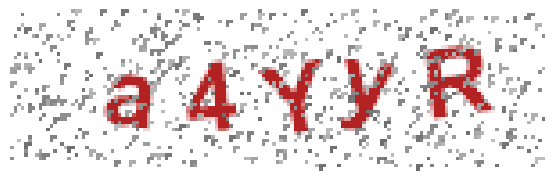

[39/200] 71171  label: a4YyR  (Vision: a4YYR)  Enter=right / type truth / s=skip / q=quit:  


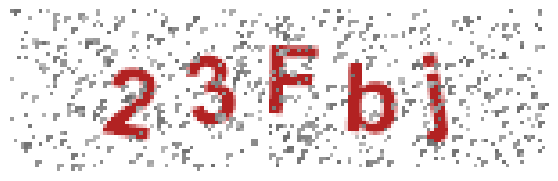

[40/200] 74385  label: 23Fbi  (Vision: 23Fbj)  Enter=right / type truth / s=skip / q=quit:  23Fbj


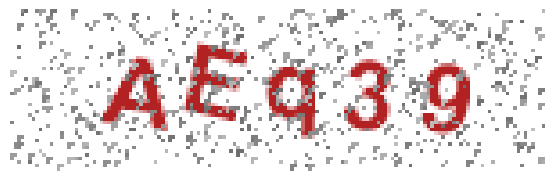

[41/200] 75452  label: AEq39  (Vision: AE439)  Enter=right / type truth / s=skip / q=quit:  


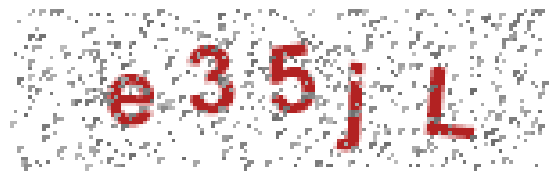

[42/200] 77021  label: a35jL  (Vision: e35jL)  Enter=right / type truth / s=skip / q=quit:  


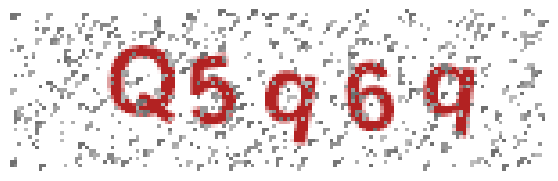

[43/200] 77307  label: Q5q5q  (Vision: Q5969)  Enter=right / type truth / s=skip / q=quit:  Q5q6q


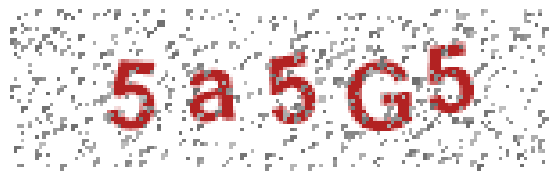

[44/200] 78893  label: 5a5G5  (Vision: 585G5)  Enter=right / type truth / s=skip / q=quit:  


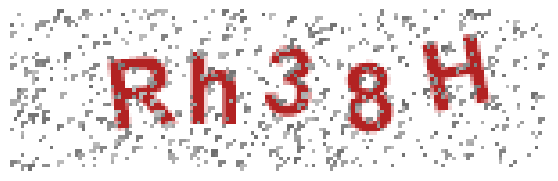

[45/200] 78928  label: Rh38H  (Vision: Rh3gH)  Enter=right / type truth / s=skip / q=quit:  


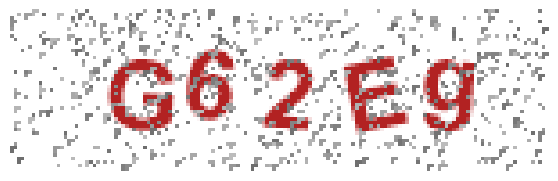

[46/200] 79061  label: G62Eg  (Vision: G62E9)  Enter=right / type truth / s=skip / q=quit:  


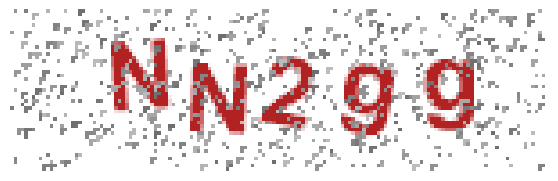

[47/200] 80203  label: NN29g  (Vision: NN299)  Enter=right / type truth / s=skip / q=quit:  NN2gg


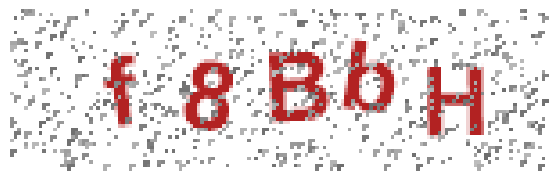

[48/200] 81344  label: f8BbH  (Vision: -)  Enter=right / type truth / s=skip / q=quit:  f8BbH


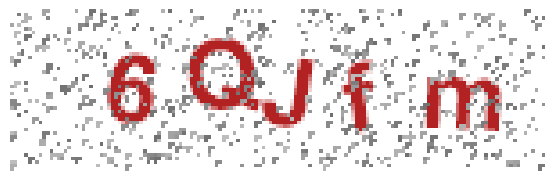

[49/200] 83231  label: 6QJim  (Vision: 6QJtm)  Enter=right / type truth / s=skip / q=quit:  6QJfm


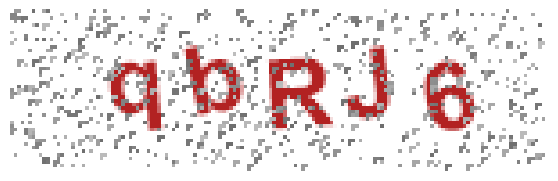

[50/200] 86070  label: qbRJ6  (Vision: abRJE)  Enter=right / type truth / s=skip / q=quit:  


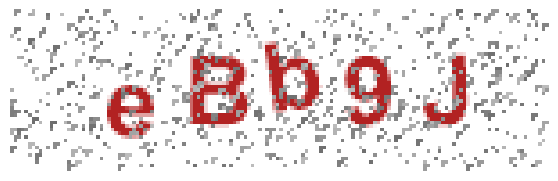

[51/200] 86540  label: eBb9J  (Vision: eBbgJ)  Enter=right / type truth / s=skip / q=quit:  


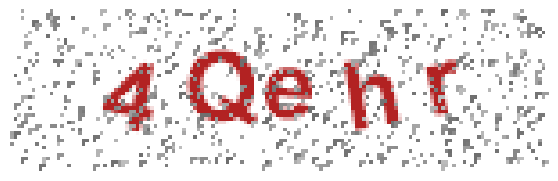

[52/200] 89044  label: 4Qahr  (Vision: 4Qehr)  Enter=right / type truth / s=skip / q=quit:  4Qehr


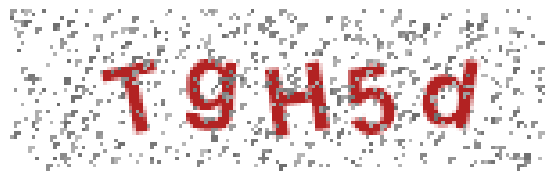

[53/200] 91662  label: TgH5d  (Vision: T9H5d)  Enter=right / type truth / s=skip / q=quit:  


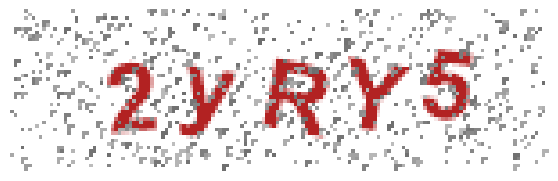

[54/200] 92443  label: 2yRY5  (Vision: 2YRY5)  Enter=right / type truth / s=skip / q=quit:  


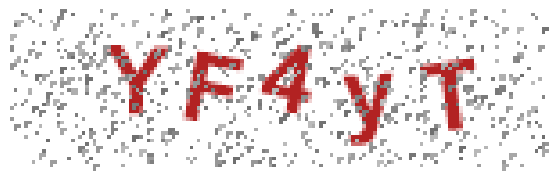

[55/200] 92611  label: YF4yT  (Vision: YF4YT)  Enter=right / type truth / s=skip / q=quit:  


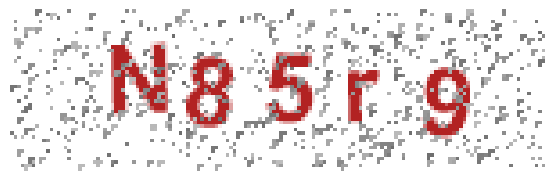

[56/200] 95878  label: N85rg  (Vision: 6f98N)  Enter=right / type truth / s=skip / q=quit:  N85r9


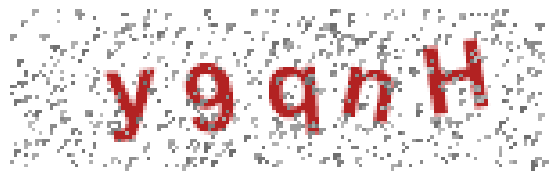

[57/200] 99301  label: y9qnH  (Vision: -)  Enter=right / type truth / s=skip / q=quit:  


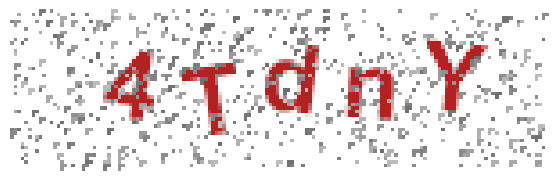

[58/200] 150  label: 4TdnY  (Vision: 4TdnY)  Enter=right / type truth / s=skip / q=quit:  


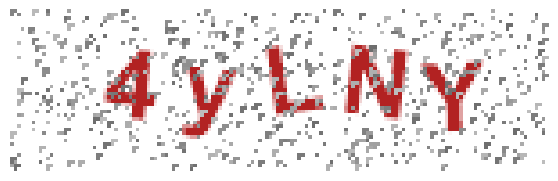

[59/200] 2125  label: 4yLNY  (Vision: 4yLNY)  Enter=right / type truth / s=skip / q=quit:  


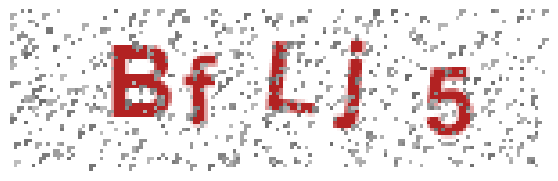

[60/200] 2836  label: BfLj5  (Vision: BfLj5)  Enter=right / type truth / s=skip / q=quit:  


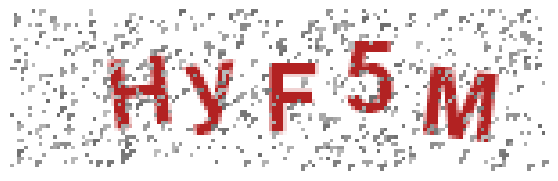

[61/200] 2987  label: HYF5M  (Vision: HYF5M)  Enter=right / type truth / s=skip / q=quit:  HyF5M


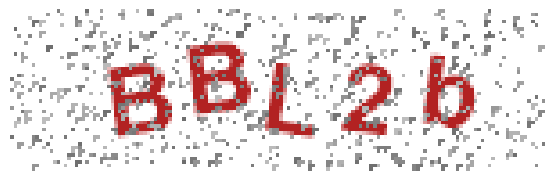

[62/200] 3500  label: BBL2b  (Vision: BBL2b)  Enter=right / type truth / s=skip / q=quit:  


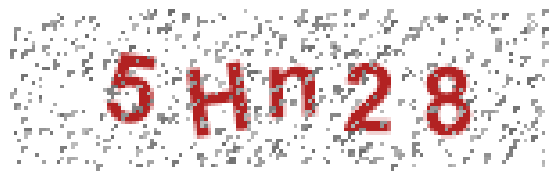

[63/200] 4770  label: 5Hn28  (Vision: 5Hn28)  Enter=right / type truth / s=skip / q=quit:  


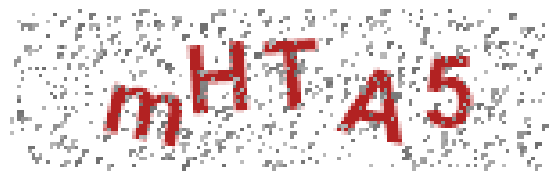

[64/200] 5065  label: mHTA5  (Vision: mHTA5)  Enter=right / type truth / s=skip / q=quit:  


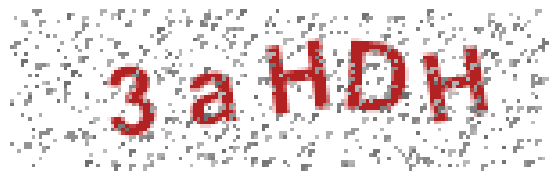

[65/200] 5307  label: 3aHDH  (Vision: 3aHDH)  Enter=right / type truth / s=skip / q=quit:  


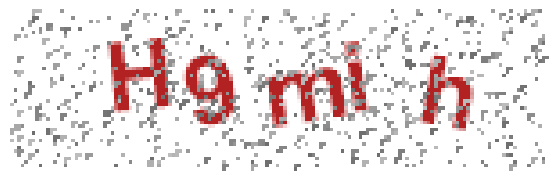

[66/200] 8007  label: H9mih  (Vision: H9mih)  Enter=right / type truth / s=skip / q=quit:  


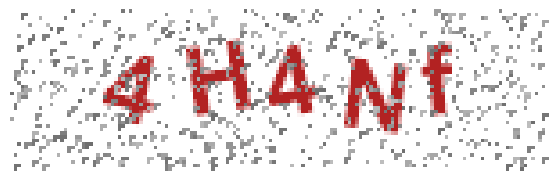

[67/200] 8152  label: 4H4Nf  (Vision: 4H4Nf)  Enter=right / type truth / s=skip / q=quit:  


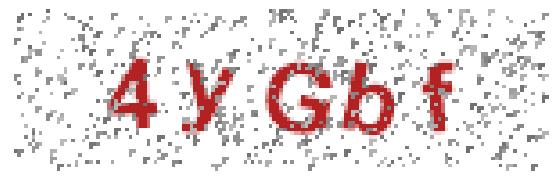

[68/200] 8164  label: 4yGbf  (Vision: 4yGbf)  Enter=right / type truth / s=skip / q=quit:  


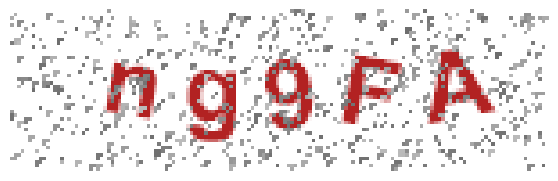

[69/200] 8256  label: ng9FA  (Vision: ng9FA)  Enter=right / type truth / s=skip / q=quit:  


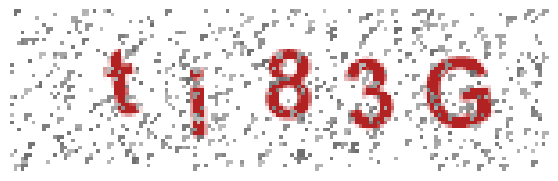

[70/200] 9056  label: ti83G  (Vision: ti83G)  Enter=right / type truth / s=skip / q=quit:  


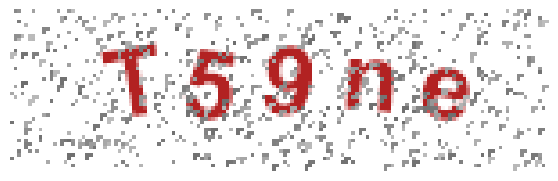

[71/200] 9176  label: T59ne  (Vision: T59ne)  Enter=right / type truth / s=skip / q=quit:  


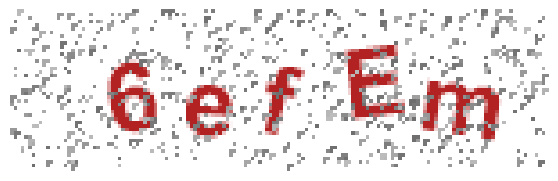

[72/200] 9434  label: 6efEm  (Vision: 6efEm)  Enter=right / type truth / s=skip / q=quit:  


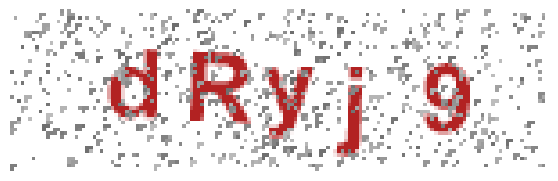

[73/200] 9666  label: dRyj9  (Vision: dRyj9)  Enter=right / type truth / s=skip / q=quit:  


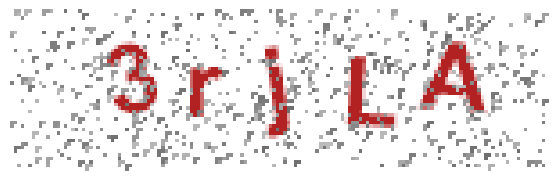

[74/200] 9699  label: 3rjLA  (Vision: 3rjLA)  Enter=right / type truth / s=skip / q=quit:  


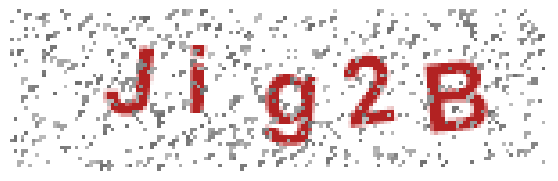

[75/200] 10519  label: Jig2B  (Vision: Jig2B)  Enter=right / type truth / s=skip / q=quit:  


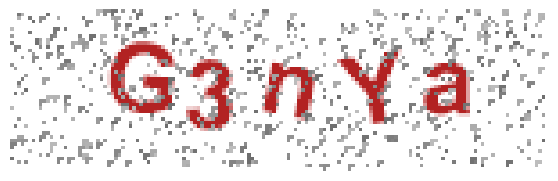

[76/200] 10545  label: G3nYa  (Vision: G3nYa)  Enter=right / type truth / s=skip / q=quit:  


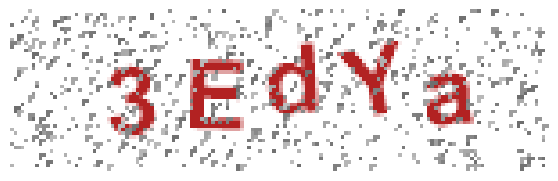

[77/200] 10797  label: 3EdYa  (Vision: 3EdYa)  Enter=right / type truth / s=skip / q=quit:  


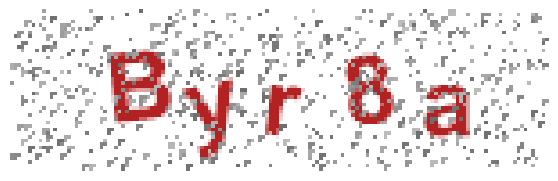

[78/200] 11774  label: Byr8a  (Vision: Byr8a)  Enter=right / type truth / s=skip / q=quit:  


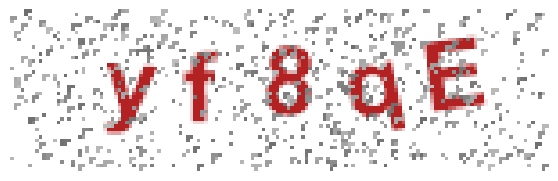

[79/200] 12011  label: yf8qE  (Vision: yf8qE)  Enter=right / type truth / s=skip / q=quit:  


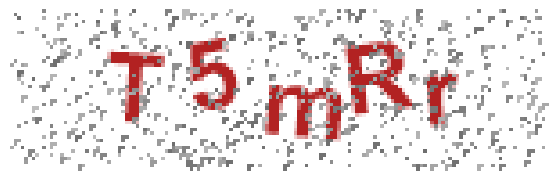

[80/200] 12430  label: T5mRr  (Vision: T5mRr)  Enter=right / type truth / s=skip / q=quit:  


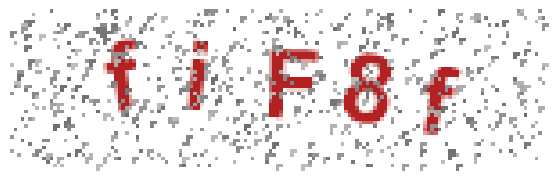

[81/200] 12946  label: fiF8f  (Vision: fiF8f)  Enter=right / type truth / s=skip / q=quit:  


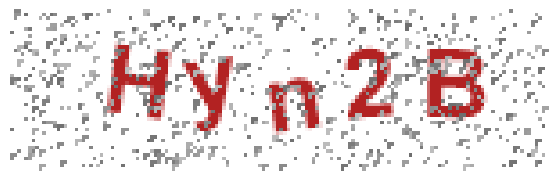

[82/200] 13187  label: Hyn2B  (Vision: Hyn2B)  Enter=right / type truth / s=skip / q=quit:  


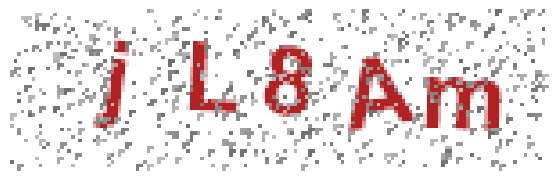

[83/200] 13200  label: jL8Am  (Vision: jL8Am)  Enter=right / type truth / s=skip / q=quit:  


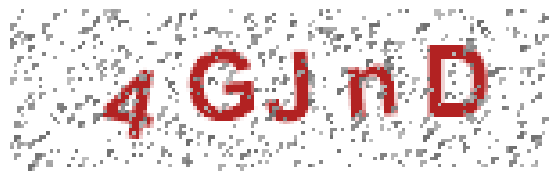

[84/200] 15120  label: 4GJnD  (Vision: 4GJnD)  Enter=right / type truth / s=skip / q=quit:  


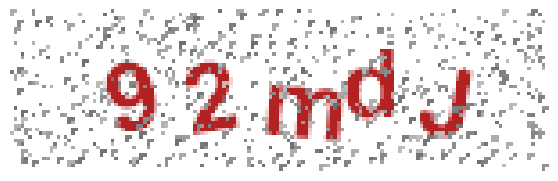

[85/200] 15211  label: 92mdJ  (Vision: 92mdJ)  Enter=right / type truth / s=skip / q=quit:  


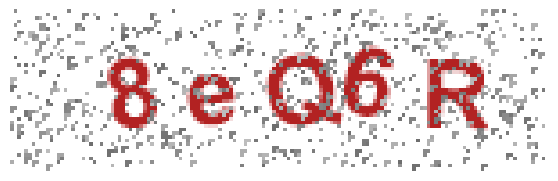

[86/200] 15354  label: 8eQ6R  (Vision: 8eQ6R)  Enter=right / type truth / s=skip / q=quit:  


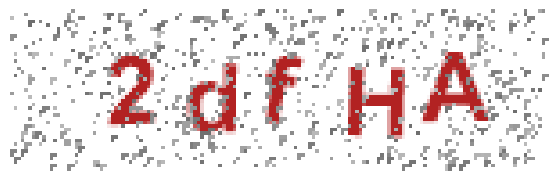

[87/200] 16240  label: 2dfHA  (Vision: 2dfHA)  Enter=right / type truth / s=skip / q=quit:  


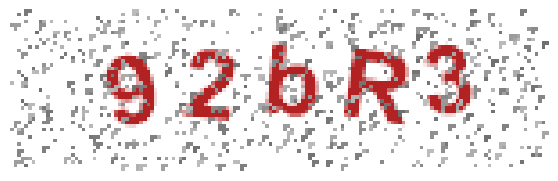

[88/200] 17069  label: 92bR3  (Vision: 92bR3)  Enter=right / type truth / s=skip / q=quit:  


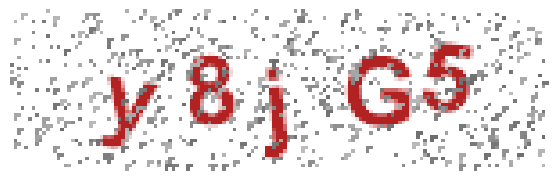

[89/200] 18255  label: y8jG5  (Vision: y8jG5)  Enter=right / type truth / s=skip / q=quit:  


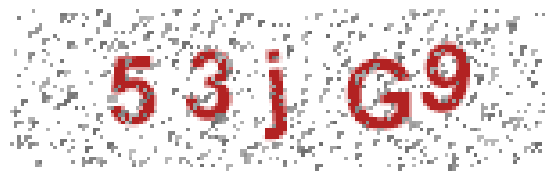

[90/200] 18317  label: 53jG9  (Vision: 53jG9)  Enter=right / type truth / s=skip / q=quit:  


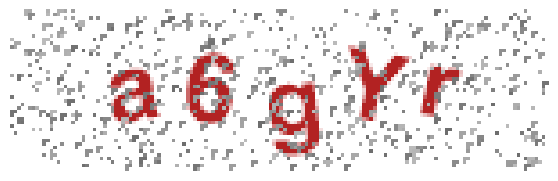

[91/200] 22346  label: a6gYr  (Vision: a6gYr)  Enter=right / type truth / s=skip / q=quit:  


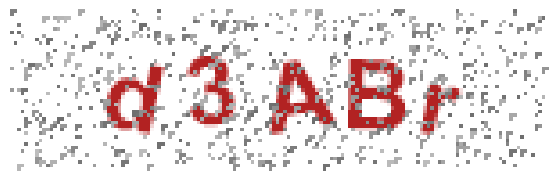

[92/200] 24101  label: d3ABr  (Vision: d3ABr)  Enter=right / type truth / s=skip / q=quit:  


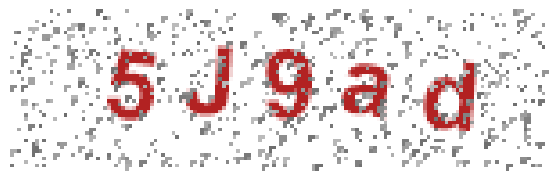

[93/200] 24245  label: 5J9ad  (Vision: 5J9ad)  Enter=right / type truth / s=skip / q=quit:  


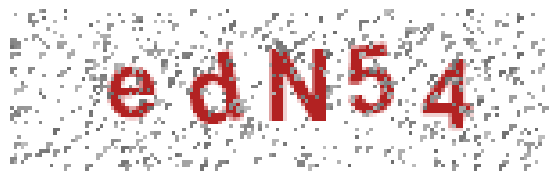

[94/200] 24476  label: edN54  (Vision: edN54)  Enter=right / type truth / s=skip / q=quit:  


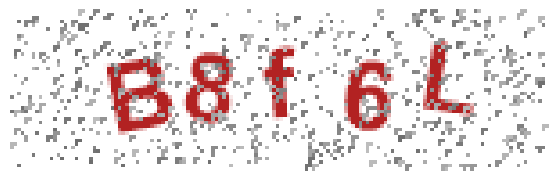

[95/200] 24710  label: B8f6L  (Vision: B8f6L)  Enter=right / type truth / s=skip / q=quit:  


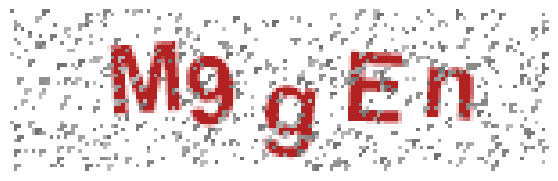

[96/200] 24824  label: M9gEn  (Vision: M9gEn)  Enter=right / type truth / s=skip / q=quit:  


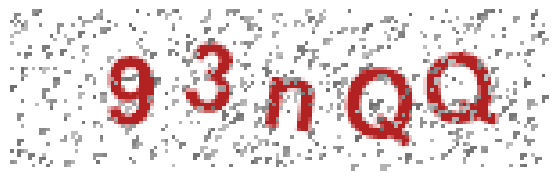

[97/200] 24954  label: 93nQQ  (Vision: 93nQQ)  Enter=right / type truth / s=skip / q=quit:  


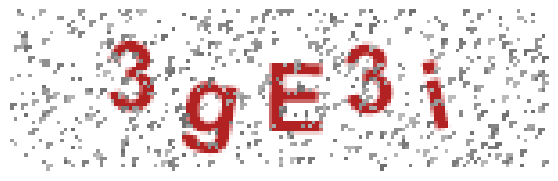

[98/200] 25044  label: 3gE3i  (Vision: 3gE3i)  Enter=right / type truth / s=skip / q=quit:  


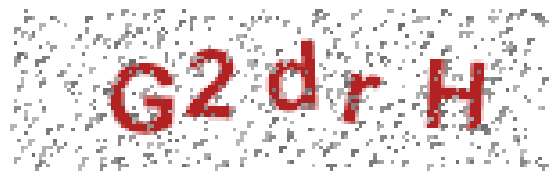

[99/200] 26635  label: G2drH  (Vision: G2drH)  Enter=right / type truth / s=skip / q=quit:  


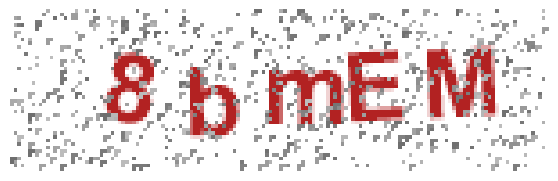

[100/200] 26802  label: 8bmEM  (Vision: 8bmEM)  Enter=right / type truth / s=skip / q=quit:  


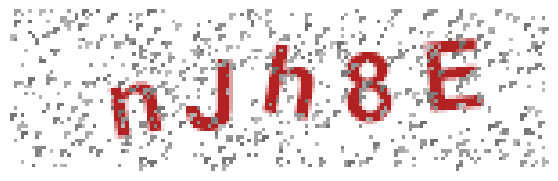

[101/200] 27601  label: nJh8E  (Vision: nJh8E)  Enter=right / type truth / s=skip / q=quit:  


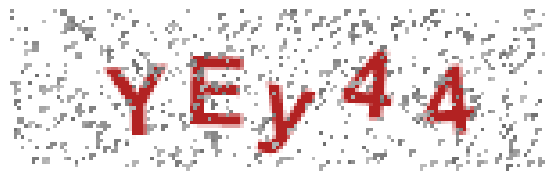

[102/200] 28207  label: YEy44  (Vision: YEy44)  Enter=right / type truth / s=skip / q=quit:  


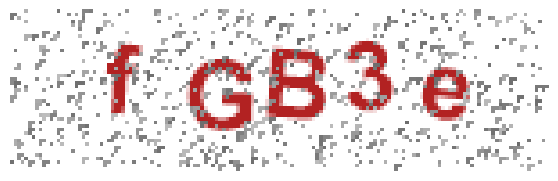

[103/200] 28632  label: fGB3e  (Vision: fGB3e)  Enter=right / type truth / s=skip / q=quit:  fGB3e


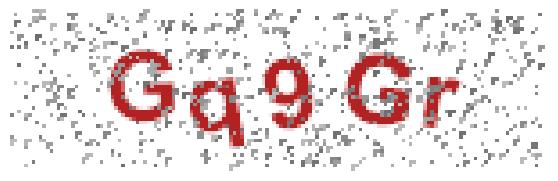

[104/200] 28897  label: Gq9Gr  (Vision: Gq9Gr)  Enter=right / type truth / s=skip / q=quit:  


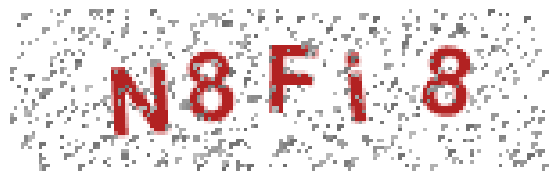

[105/200] 28945  label: N8Fi8  (Vision: N8Fi8)  Enter=right / type truth / s=skip / q=quit:  


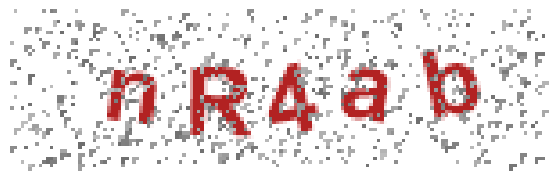

[106/200] 29060  label: nR4ab  (Vision: nR4ab)  Enter=right / type truth / s=skip / q=quit:  


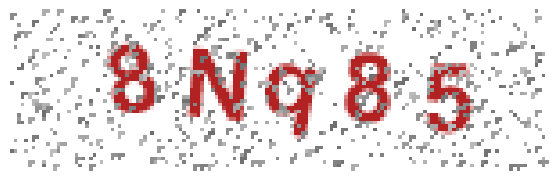

[107/200] 31276  label: 8Nq85  (Vision: 8Nq85)  Enter=right / type truth / s=skip / q=quit:  


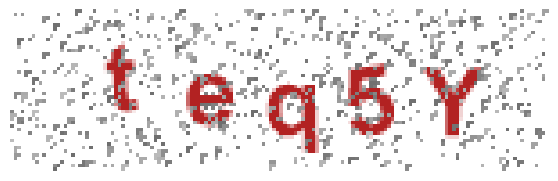

[108/200] 31856  label: teq5Y  (Vision: teq5Y)  Enter=right / type truth / s=skip / q=quit:  


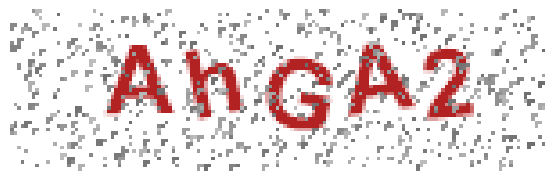

[109/200] 31970  label: AhGA2  (Vision: AhGA2)  Enter=right / type truth / s=skip / q=quit:  


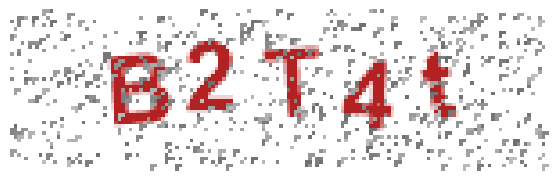

[110/200] 32835  label: B2T4t  (Vision: B2T4t)  Enter=right / type truth / s=skip / q=quit:  


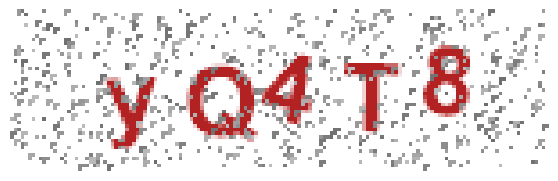

[111/200] 33937  label: yQ4T8  (Vision: yQ4T8)  Enter=right / type truth / s=skip / q=quit:  


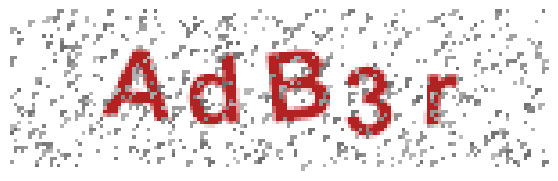

[112/200] 34069  label: AdB3r  (Vision: AdB3r)  Enter=right / type truth / s=skip / q=quit:  


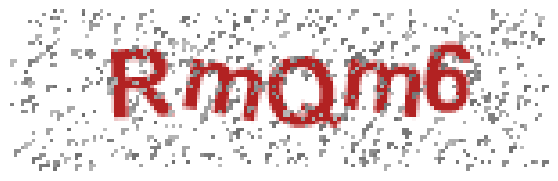

[113/200] 34087  label: RmQm6  (Vision: RmQm6)  Enter=right / type truth / s=skip / q=quit:  


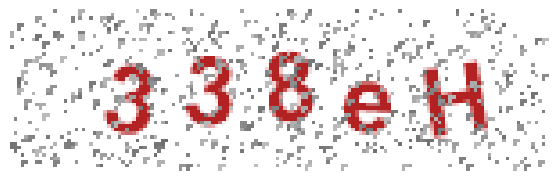

[114/200] 34144  label: 338eH  (Vision: 338eH)  Enter=right / type truth / s=skip / q=quit:  


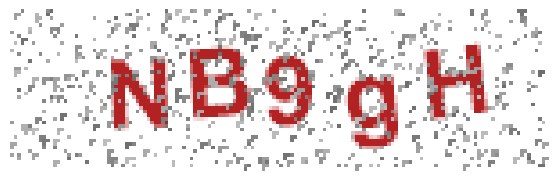

[115/200] 35526  label: NB9gH  (Vision: NB9gH)  Enter=right / type truth / s=skip / q=quit:  


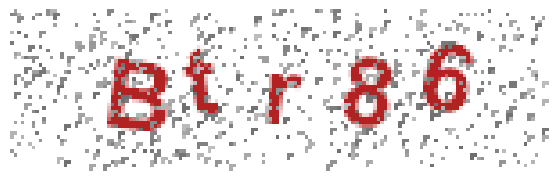

[116/200] 36128  label: Btr86  (Vision: Btr86)  Enter=right / type truth / s=skip / q=quit:  


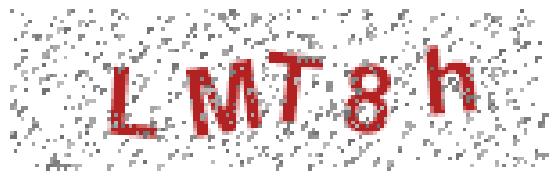

[117/200] 36942  label: LMT8h  (Vision: LMT8h)  Enter=right / type truth / s=skip / q=quit:  


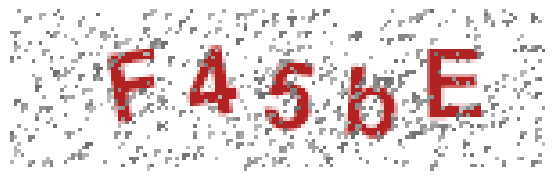

[118/200] 37704  label: F45bE  (Vision: F45bE)  Enter=right / type truth / s=skip / q=quit:  


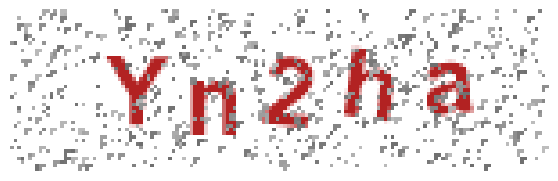

[119/200] 38154  label: Yn2ha  (Vision: Yn2ha)  Enter=right / type truth / s=skip / q=quit:  


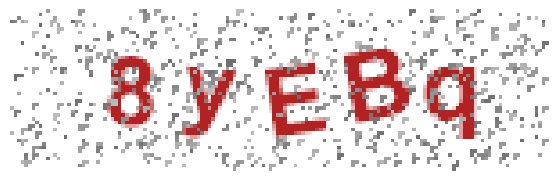

[120/200] 39461  label: 8yEBq  (Vision: 8yEBq)  Enter=right / type truth / s=skip / q=quit:  


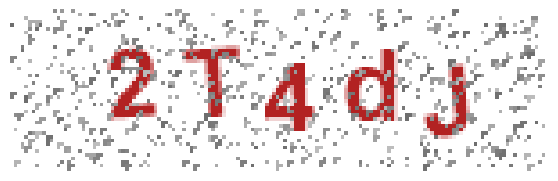

[121/200] 39512  label: 2T4dJ  (Vision: 2T4dJ)  Enter=right / type truth / s=skip / q=quit:  


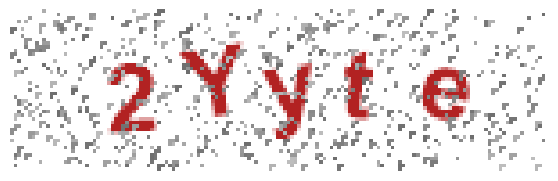

[122/200] 39756  label: 2Yyte  (Vision: 2Yyte)  Enter=right / type truth / s=skip / q=quit:  


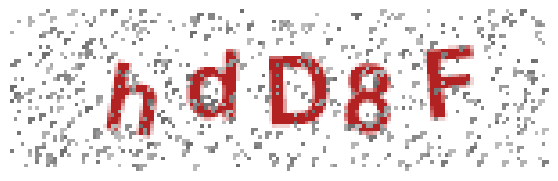

[123/200] 40652  label: hdD8F  (Vision: hdD8F)  Enter=right / type truth / s=skip / q=quit:  


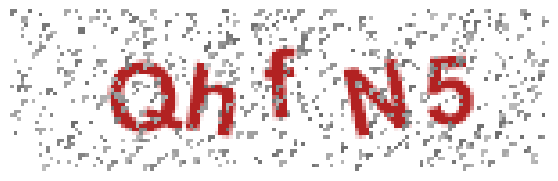

[124/200] 41445  label: QhfN5  (Vision: QhfN5)  Enter=right / type truth / s=skip / q=quit:  


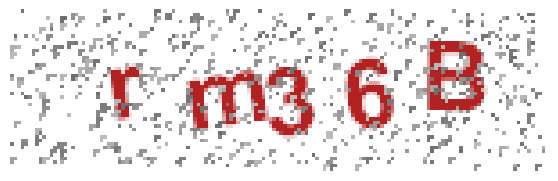

[125/200] 41556  label: rm36B  (Vision: rm36B)  Enter=right / type truth / s=skip / q=quit:  


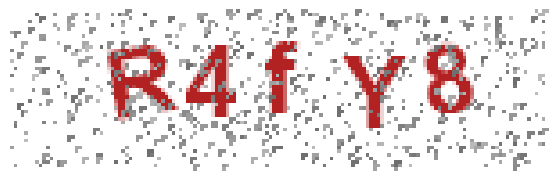

[126/200] 41951  label: R4fY8  (Vision: R4fY8)  Enter=right / type truth / s=skip / q=quit:  


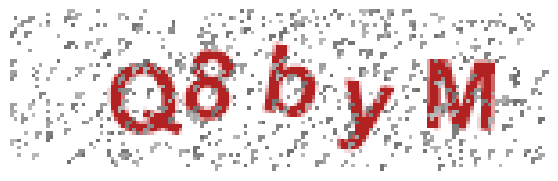

[127/200] 42510  label: Q8byM  (Vision: Q8byM)  Enter=right / type truth / s=skip / q=quit:  


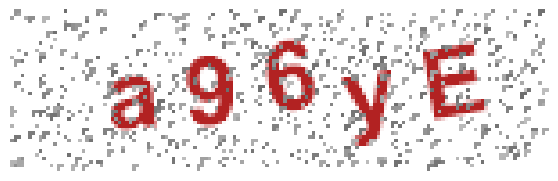

[128/200] 43280  label: a96yE  (Vision: a96yE)  Enter=right / type truth / s=skip / q=quit:  


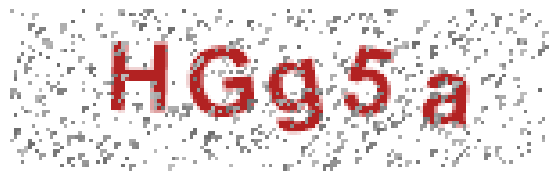

[129/200] 43665  label: HGg5a  (Vision: HGg5a)  Enter=right / type truth / s=skip / q=quit:  


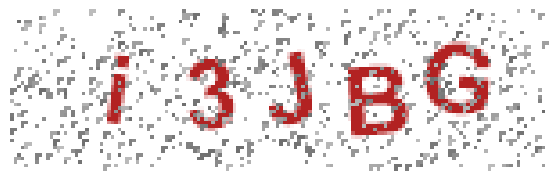

[130/200] 43945  label: i3JBG  (Vision: i3JBG)  Enter=right / type truth / s=skip / q=quit:  


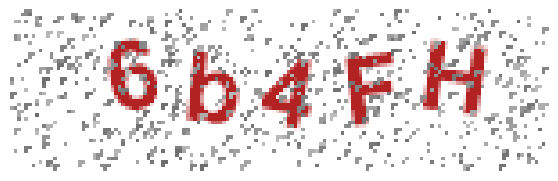

[131/200] 46373  label: 6b4FH  (Vision: 6b4FH)  Enter=right / type truth / s=skip / q=quit:  


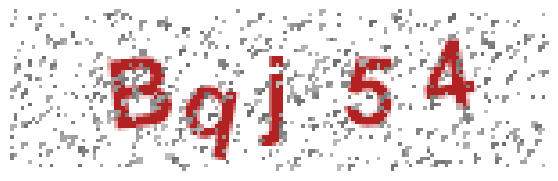

[132/200] 46931  label: Bqj54  (Vision: Bqj54)  Enter=right / type truth / s=skip / q=quit:  


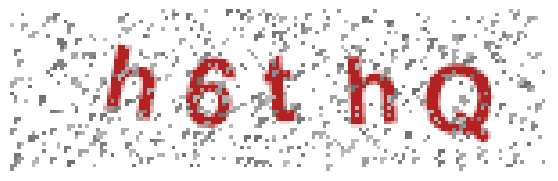

[133/200] 48767  label: h6thQ  (Vision: h6thQ)  Enter=right / type truth / s=skip / q=quit:  


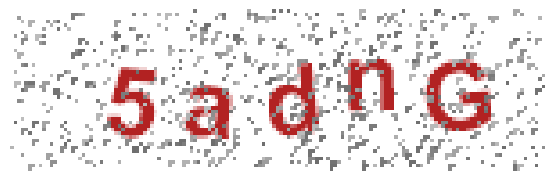

[134/200] 50450  label: 5adnG  (Vision: 5adnG)  Enter=right / type truth / s=skip / q=quit:  


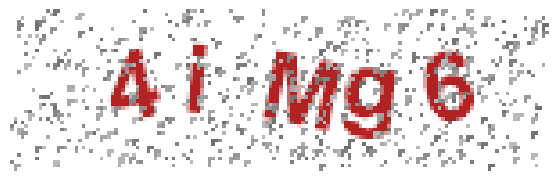

[135/200] 50495  label: 4iMg6  (Vision: 4iMg6)  Enter=right / type truth / s=skip / q=quit:  


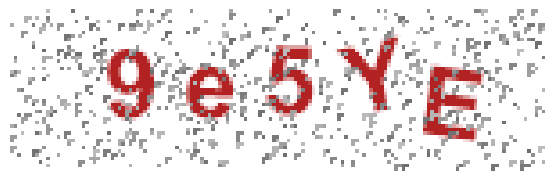

[136/200] 51277  label: 9e5YE  (Vision: 9e5YE)  Enter=right / type truth / s=skip / q=quit:  


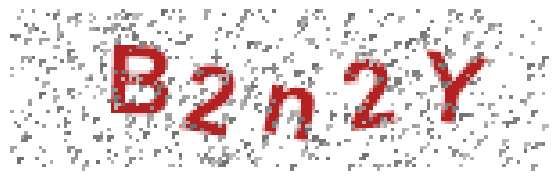

[137/200] 52275  label: B2n2Y  (Vision: B2n2Y)  Enter=right / type truth / s=skip / q=quit:  


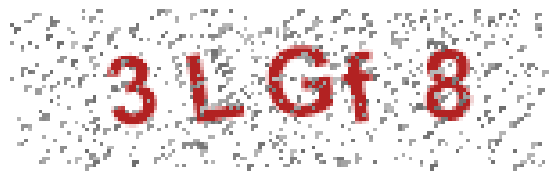

[138/200] 53076  label: 3LGf8  (Vision: 3LGf8)  Enter=right / type truth / s=skip / q=quit:  


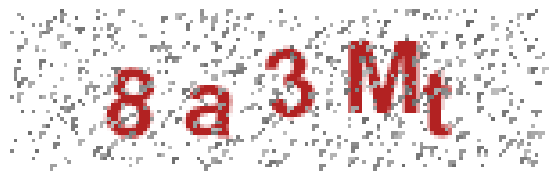

[139/200] 55126  label: 8a3Mt  (Vision: 8a3Mt)  Enter=right / type truth / s=skip / q=quit:  


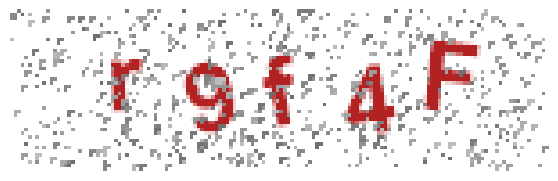

[140/200] 55854  label: rgf4F  (Vision: rgf4F)  Enter=right / type truth / s=skip / q=quit:  r9f4F


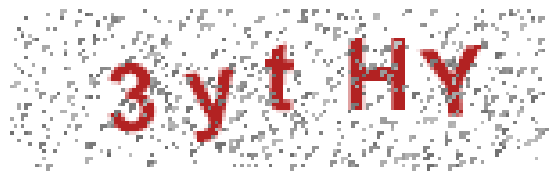

[141/200] 58326  label: 3ytHY  (Vision: 3ytHY)  Enter=right / type truth / s=skip / q=quit:  


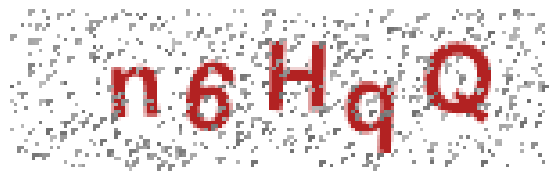

[142/200] 58717  label: n6HqQ  (Vision: n6HqQ)  Enter=right / type truth / s=skip / q=quit:  


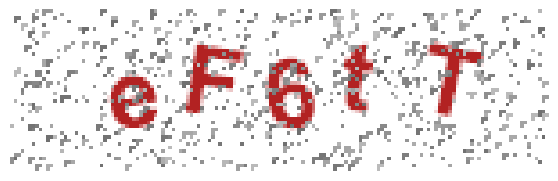

[143/200] 59057  label: eF6tT  (Vision: eF6tT)  Enter=right / type truth / s=skip / q=quit:  


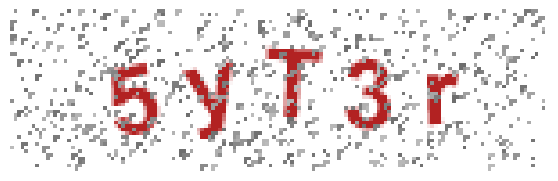

[144/200] 61885  label: 5yT3r  (Vision: 5yT3r)  Enter=right / type truth / s=skip / q=quit:  


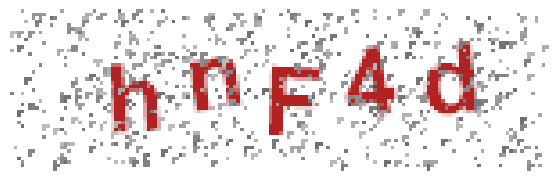

[145/200] 62815  label: hnF4d  (Vision: hnF4d)  Enter=right / type truth / s=skip / q=quit:  


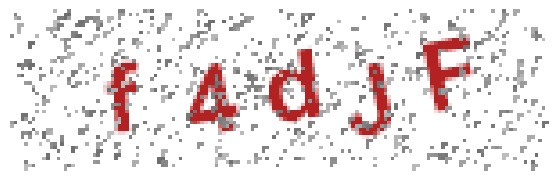

[146/200] 63692  label: f4dJF  (Vision: f4dJF)  Enter=right / type truth / s=skip / q=quit:  


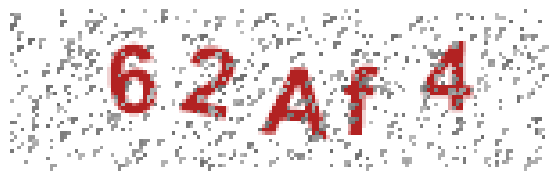

[147/200] 64132  label: 62Af4  (Vision: 62Af4)  Enter=right / type truth / s=skip / q=quit:  


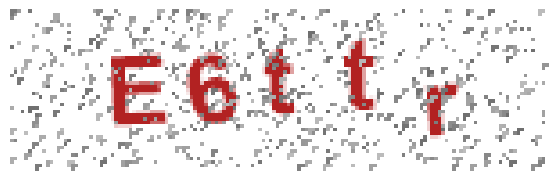

[148/200] 64574  label: E6ttr  (Vision: E6ttr)  Enter=right / type truth / s=skip / q=quit:  


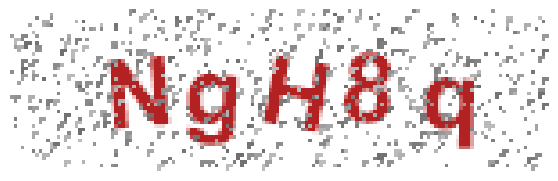

[149/200] 64695  label: NgH8q  (Vision: NgH8q)  Enter=right / type truth / s=skip / q=quit:  


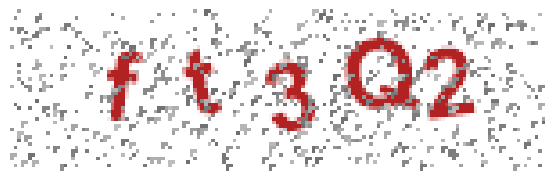

[150/200] 66151  label: ft3Q2  (Vision: ft3Q2)  Enter=right / type truth / s=skip / q=quit:  


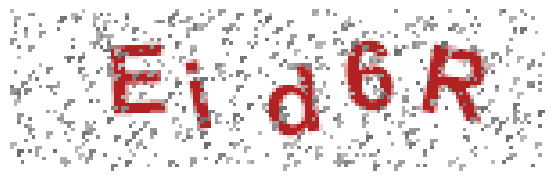

[151/200] 67014  label: Eid6R  (Vision: Eid6R)  Enter=right / type truth / s=skip / q=quit:  


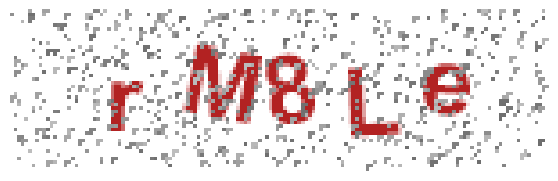

[152/200] 68335  label: rM8Le  (Vision: rM8Le)  Enter=right / type truth / s=skip / q=quit:  


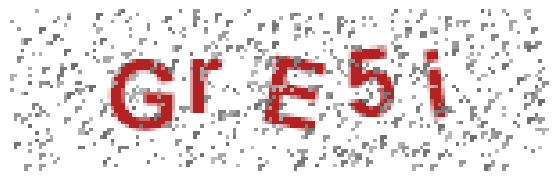

[153/200] 68757  label: GrE5i  (Vision: GrE5i)  Enter=right / type truth / s=skip / q=quit:  


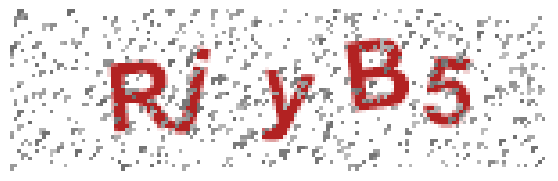

[154/200] 69805  label: RjyB5  (Vision: RjyB5)  Enter=right / type truth / s=skip / q=quit:  


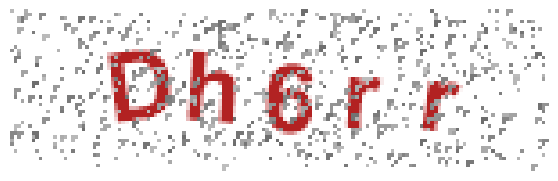

[155/200] 70019  label: Dh6rr  (Vision: Dh6rr)  Enter=right / type truth / s=skip / q=quit:  


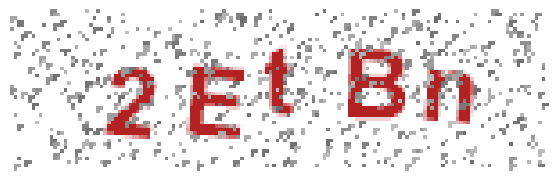

[156/200] 70858  label: 2EtBn  (Vision: 2EtBn)  Enter=right / type truth / s=skip / q=quit:  


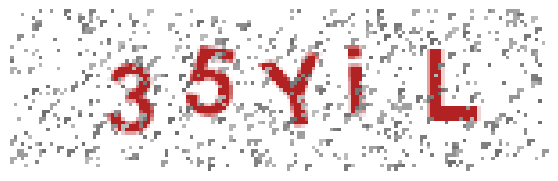

[157/200] 71335  label: 35YiL  (Vision: 35YiL)  Enter=right / type truth / s=skip / q=quit:  


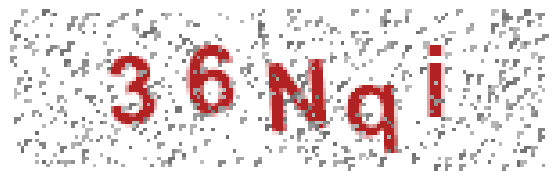

[158/200] 71727  label: 36Nqi  (Vision: 36Nqi)  Enter=right / type truth / s=skip / q=quit:  


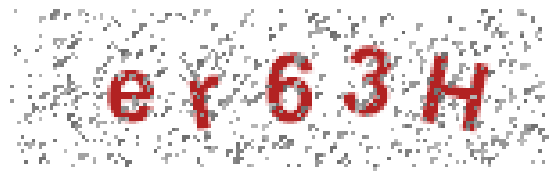

[159/200] 71755  label: er63H  (Vision: er63H)  Enter=right / type truth / s=skip / q=quit:  


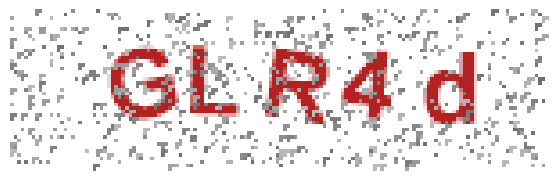

[160/200] 71920  label: GLR4d  (Vision: GLR4d)  Enter=right / type truth / s=skip / q=quit:  


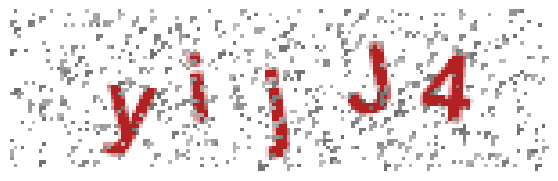

[161/200] 72256  label: yijJ4  (Vision: yijJ4)  Enter=right / type truth / s=skip / q=quit:  


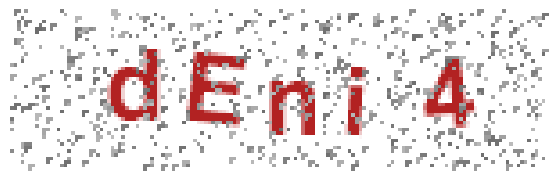

[162/200] 72421  label: dEni4  (Vision: dEni4)  Enter=right / type truth / s=skip / q=quit:  


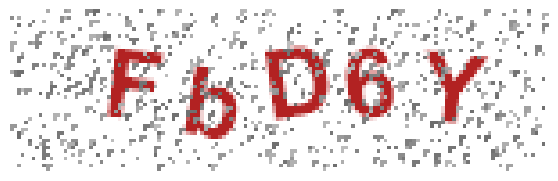

[163/200] 73376  label: FbD6Y  (Vision: FbD6Y)  Enter=right / type truth / s=skip / q=quit:  


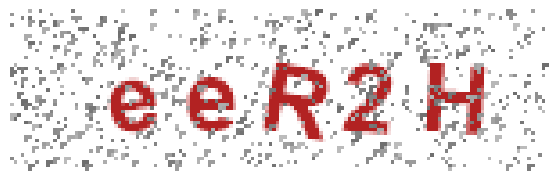

[164/200] 75218  label: eeR2H  (Vision: eeR2H)  Enter=right / type truth / s=skip / q=quit:  


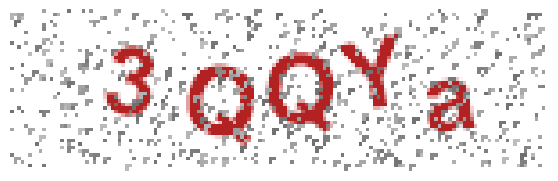

[165/200] 75492  label: 3QQYa  (Vision: 3QQYa)  Enter=right / type truth / s=skip / q=quit:  


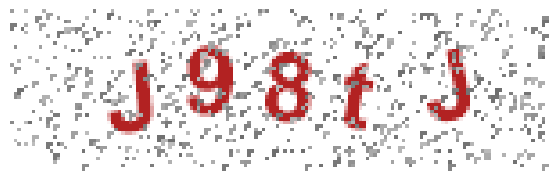

[166/200] 75982  label: J98tJ  (Vision: J98tJ)  Enter=right / type truth / s=skip / q=quit:  


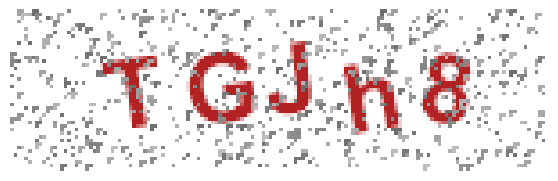

[167/200] 76466  label: TGJh8  (Vision: TGJh8)  Enter=right / type truth / s=skip / q=quit:  


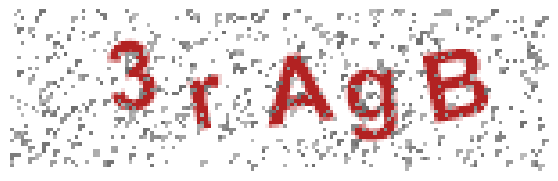

[168/200] 76950  label: 3rAgB  (Vision: 3rAgB)  Enter=right / type truth / s=skip / q=quit:  


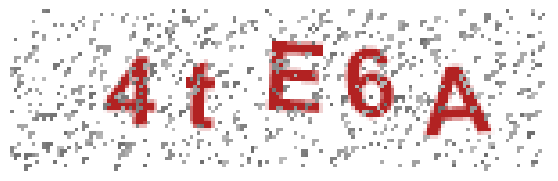

[169/200] 78157  label: 4tE6A  (Vision: 4tE6A)  Enter=right / type truth / s=skip / q=quit:  


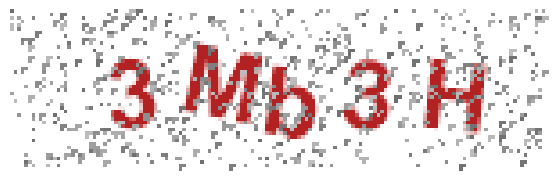

[170/200] 79365  label: 3Mb3H  (Vision: 3Mb3H)  Enter=right / type truth / s=skip / q=quit:  


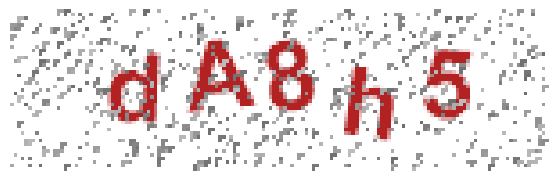

[171/200] 79474  label: dA8h5  (Vision: dA8h5)  Enter=right / type truth / s=skip / q=quit:  


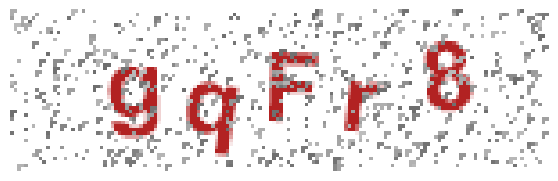

[172/200] 80071  label: gqFr8  (Vision: gqFr8)  Enter=right / type truth / s=skip / q=quit:  


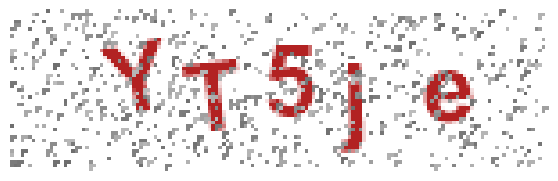

[173/200] 80318  label: YT5je  (Vision: YT5je)  Enter=right / type truth / s=skip / q=quit:  


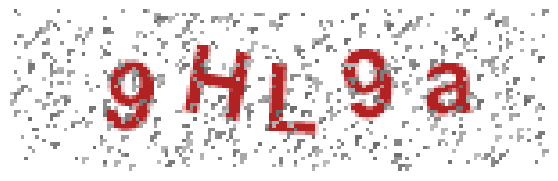

[174/200] 80319  label: 9HL9a  (Vision: 9HL9a)  Enter=right / type truth / s=skip / q=quit:  


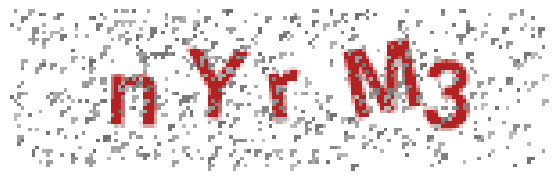

[175/200] 81051  label: nYrM3  (Vision: nYrM3)  Enter=right / type truth / s=skip / q=quit:  


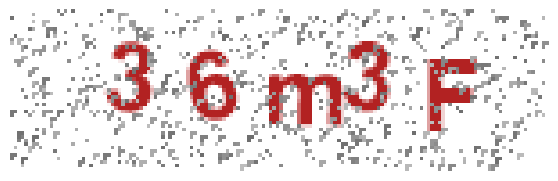

[176/200] 81955  label: 36m3F  (Vision: 36m3F)  Enter=right / type truth / s=skip / q=quit:  


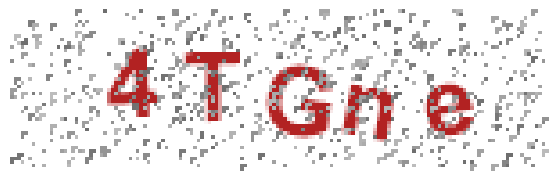

[177/200] 82595  label: 4TGne  (Vision: 4TGne)  Enter=right / type truth / s=skip / q=quit:  


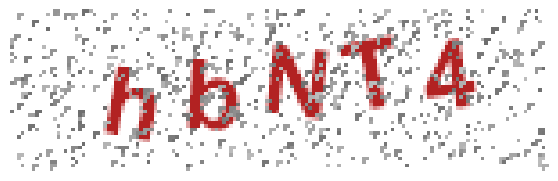

[178/200] 83127  label: hbNT4  (Vision: hbNT4)  Enter=right / type truth / s=skip / q=quit:  


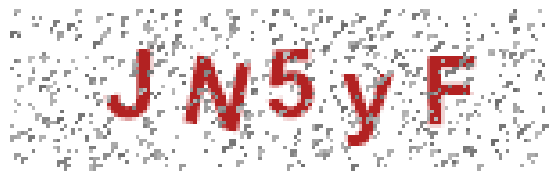

[179/200] 83942  label: JN5yF  (Vision: JN5yF)  Enter=right / type truth / s=skip / q=quit:  


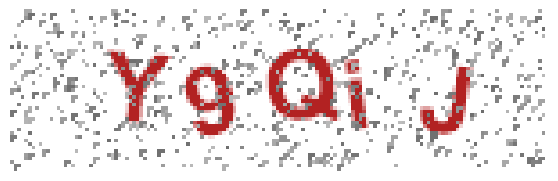

[180/200] 84043  label: YgQiJ  (Vision: YgQiJ)  Enter=right / type truth / s=skip / q=quit:  


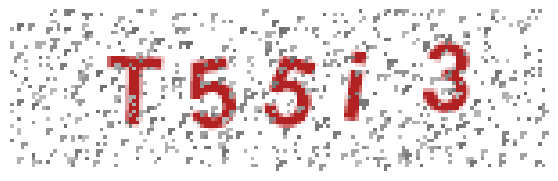

[181/200] 84794  label: T55i3  (Vision: T55i3)  Enter=right / type truth / s=skip / q=quit:  


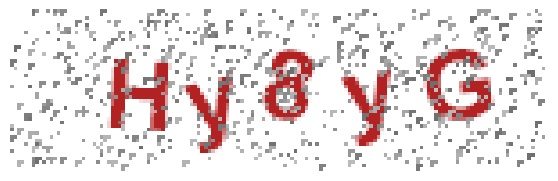

[182/200] 87577  label: Hy8yG  (Vision: Hy8yG)  Enter=right / type truth / s=skip / q=quit:  


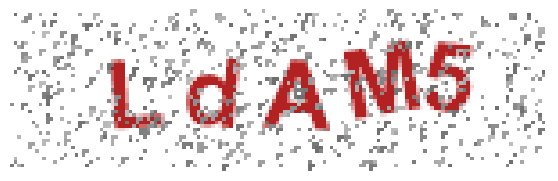

[183/200] 88962  label: LdAM5  (Vision: LdAM5)  Enter=right / type truth / s=skip / q=quit:  


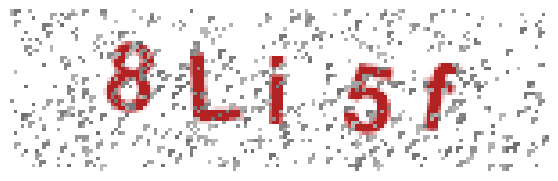

[184/200] 89061  label: 8Li5f  (Vision: 8Li5f)  Enter=right / type truth / s=skip / q=quit:  


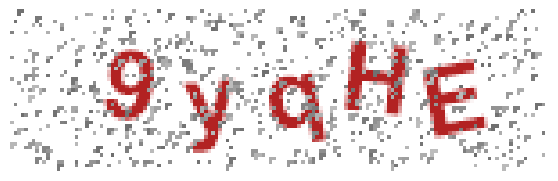

[185/200] 89207  label: 9yqHE  (Vision: 9yqHE)  Enter=right / type truth / s=skip / q=quit:  


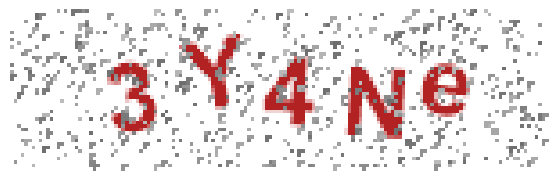

[186/200] 89588  label: 3Y4Ne  (Vision: 3Y4Ne)  Enter=right / type truth / s=skip / q=quit:  


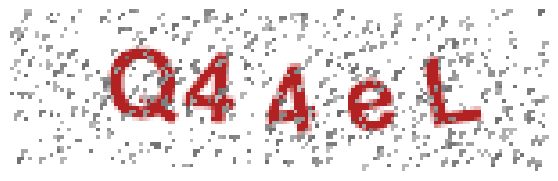

[187/200] 89652  label: Q44eL  (Vision: Q44eL)  Enter=right / type truth / s=skip / q=quit:  


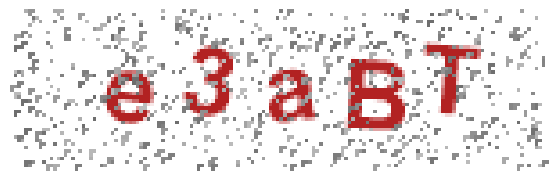

[188/200] 91446  label: e3aBT  (Vision: e3aBT)  Enter=right / type truth / s=skip / q=quit:  


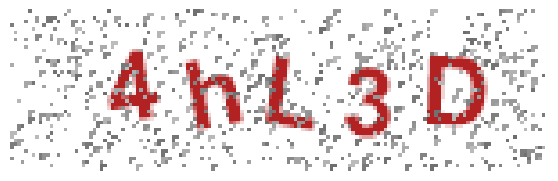

[189/200] 91780  label: 4hL3D  (Vision: 4hL3D)  Enter=right / type truth / s=skip / q=quit:  


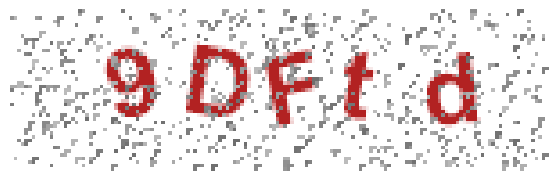

[190/200] 92228  label: 9DFtd  (Vision: 9DFtd)  Enter=right / type truth / s=skip / q=quit:  


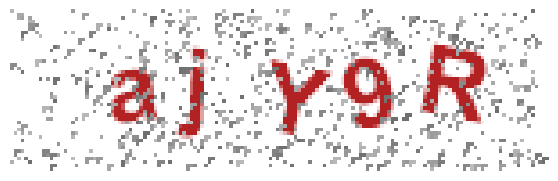

[191/200] 92429  label: ajY9R  (Vision: ajY9R)  Enter=right / type truth / s=skip / q=quit:  


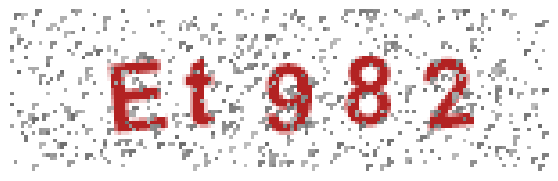

[192/200] 92450  label: Et982  (Vision: Et982)  Enter=right / type truth / s=skip / q=quit:  


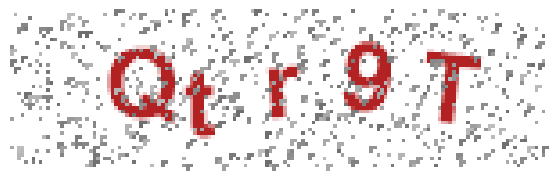

[193/200] 93095  label: Qtr9T  (Vision: Qtr9T)  Enter=right / type truth / s=skip / q=quit:  


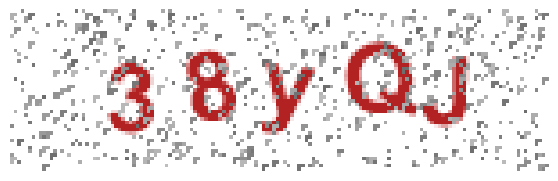

[194/200] 94125  label: 38yQJ  (Vision: 38yQJ)  Enter=right / type truth / s=skip / q=quit:  


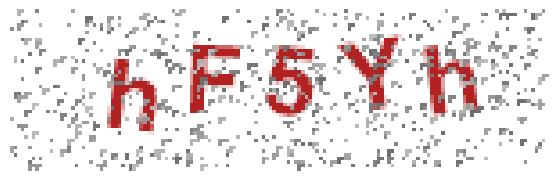

[195/200] 94334  label: hF5Yh  (Vision: hF5Yh)  Enter=right / type truth / s=skip / q=quit:  


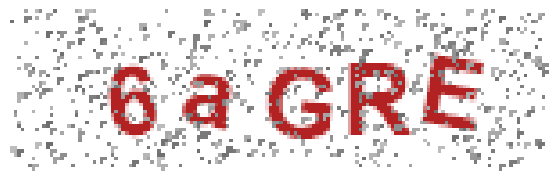

[196/200] 95310  label: 6aGRE  (Vision: 6aGRE)  Enter=right / type truth / s=skip / q=quit:  


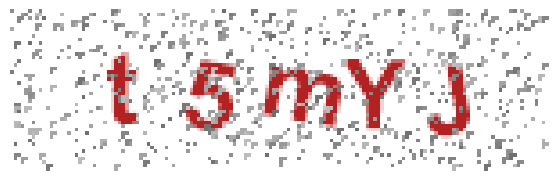

[197/200] 95661  label: t5mYJ  (Vision: t5mYJ)  Enter=right / type truth / s=skip / q=quit:  


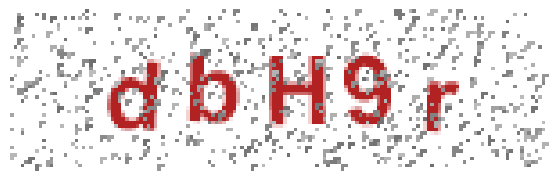

[198/200] 95720  label: dbH9r  (Vision: dbH9r)  Enter=right / type truth / s=skip / q=quit:  


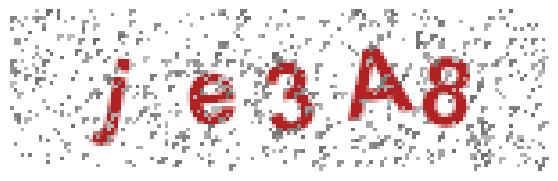

[199/200] 99065  label: je3A8  (Vision: je3A8)  Enter=right / type truth / s=skip / q=quit:  


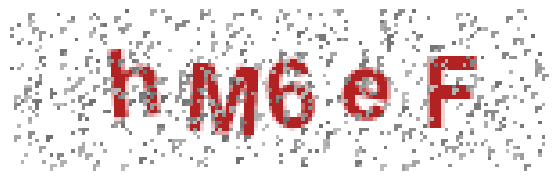

[200/200] 99347  label: hM6eF  (Vision: hM6eF)  Enter=right / type truth / s=skip / q=quit:  



18 labels corrected: 4322: HiyR5 -> HjyR8, 14295: nHiT9 -> nHjT9, 15689: a2qaM -> e2qaM, 16360: G4Ri8 -> G4Rj8, 19184: 5TemN -> 6TemN, 36073: FGq5A -> FGq6A, 42626: 43Rii -> 43Rfi, 43615: MDie6 -> MDje6, 55787: J5iiD -> J5irD, 66577: gDLgE -> gDL8E, 74385: 23Fbi -> 23Fbj, 77307: Q5q5q -> Q5q6q, 80203: NN29g -> NN2gg, 83231: 6QJim -> 6QJfm, 89044: 4Qahr -> 4Qehr, 95878: N85rg -> N85r9, 2987: HYF5M -> HyF5M, 55854: rgf4F -> r9f4F
200/200 gold checked


In [4]:
%run -i ../scripts/audit_gold.py

## 5. Relabel every captcha with the teacher; agree with Vision = training label (~30 s)

In [6]:
%run -i ../scripts/relabel.py

wrote ../data/labels.csv: 66105 agree + 0 reviews to train on, 33695 disagree (review queue); gold's 200 left out
  of the disagreements, Vision gave no valid read on 6991
  teacher confidence < 0.3:   2644 images (2.6%)
  teacher confidence < 0.5:  16987 images (17.0%)
  teacher confidence < 0.7:  45185 images (45.3%)


## 6. Labels and splits
**agree** labels split 70/20/10 into train / test / val; your reviews all go to train; **disagree** is not used;
gold stays apart. Val and test measure agreement with teacher + Vision, so they read high: only **gold** is the real score.

In [8]:
with open(LABELS_CSV) as f:
    rows = list(csv.DictReader(f))
assert not any(r["id"] in GOLD for r in rows), "a gold captcha is in the training labels"
auto = [r for r in rows if r["source"] == "agree"]
reviewed = [r for r in rows if r["source"] == "review"]
random.Random(SEED).shuffle(auto)
n_train, n_test = int(0.7 * len(auto)), int(0.2 * len(auto))

def gold_rows():
    """Gold rows the model can be scored on (labels within its alphabet)."""
    return [{"id": i, "label": g["label"]} for i, g in GOLD.items() if set(g["label"]) <= set(ALPHABET)]

split_rows = {
    "train": auto[:n_train] + reviewed,
    "test": auto[n_train:n_train + n_test],
    "val": auto[n_train + n_test:],
    "gold": gold_rows(),
}

def encode(label):
    return [CHAR_TO_IDX[c] for c in label]

def decode_pred(p):
    return "".join(ALPHABET[i] for i in p)

data = {name: (torch.tensor([row_of[r["id"]] for r in rs]), torch.tensor([encode(r["label"]) for r in rs]))
        for name, rs in split_rows.items()}
print({k: len(v) for k, v in split_rows.items()}, f"(train includes {len(reviewed)} reviews)")
if len(split_rows["gold"]) < len(GOLD):
    print(f"{len(GOLD) - len(split_rows['gold'])} gold captchas use characters outside the alphabet: not scored")

{'train': 46273, 'test': 13221, 'val': 6611, 'gold': 200} (train includes 0 reviews)


## 7. Batching and augmentation (preview: originals on top, augmented below)

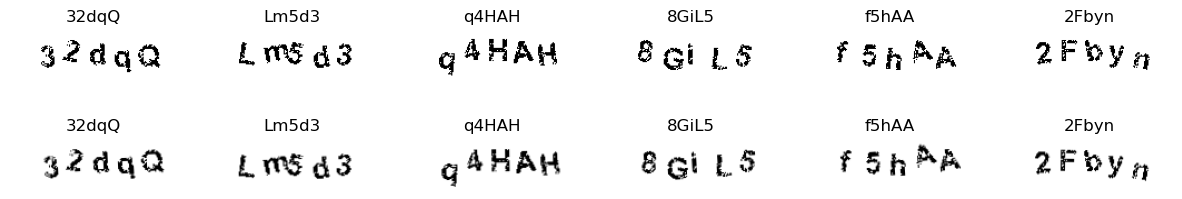

In [9]:
def batches(split, batch_size, shuffle):
    idx, y = data[split]
    order = torch.randperm(len(idx)) if shuffle else torch.arange(len(idx))
    for k in range(0, len(idx), batch_size):
        j = order[k:k + batch_size]
        yield to_input(X[idx[j].to(DEVICE)]), y[j].to(DEVICE)

def augment(x, max_shift=4, max_rot=4):
    """Random shift (px) and rotation (degrees) per image, whole batch at once on the GPU.
    No flips: a mirrored letter is a different letter."""
    b, _, h, w = x.shape
    rnd = lambda: torch.rand(b, device=x.device) * 2 - 1
    ang = rnd() * max_rot * math.pi / 180
    cos, sin = torch.cos(ang), torch.sin(ang)
    tx, ty = rnd() * max_shift * 2 / w, rnd() * max_shift * 2 / h
    theta = torch.stack([torch.stack([cos, -sin * h / w, tx], 1),
                         torch.stack([sin * w / h, cos, ty], 1)], 1)
    grid = F.affine_grid(theta, x.shape, align_corners=False)
    return F.grid_sample(x, grid, padding_mode="zeros", align_corners=False)

x, y = next(batches("train", 6, shuffle=True))
fig, ax = plt.subplots(2, 6, figsize=(15, 2.6))
for k, img in enumerate(torch.cat([x, augment(x)]).cpu()):
    ax[k // 6, k % 6].imshow(img[0], cmap="gray_r", vmin=0, vmax=1)
    ax[k // 6, k % 6].set_title(decode_pred(y[k % 6].tolist()))
    ax[k // 6, k % 6].axis("off")
plt.show()

## 8. Training and evaluation functions

In [10]:
@torch.no_grad()
def predict(model, split, batch_size=1024):
    model.eval()
    return torch.cat([model(x).argmax(-1).cpu() for x, _ in batches(split, batch_size, shuffle=False)])

def evaluate(model, split):
    p, y = predict(model, split), data[split][1]
    return {"exact": (p == y).all(1).float().mean().item(), "char": (p == y).float().mean().item()}

def train(cfg, tag=""):
    """Trains with cfg; keeps the epoch with the best val exact-match. Returns (model, best val)."""
    torch.manual_seed(cfg["seed"])
    model = CaptchaCNN(len(ALPHABET), dropout=cfg["dropout"]).to(DEVICE)
    if cfg["init"]:   # start from a trained model's weights instead of random ones
        model.load_state_dict(torch.load(cfg["init"], map_location=DEVICE)["state_dict"])
    opt = torch.optim.AdamW(model.parameters(), lr=cfg["lr"], weight_decay=cfg["weight_decay"])
    steps_per_epoch = math.ceil(len(data["train"][0]) / cfg["batch"])
    sched = torch.optim.lr_scheduler.OneCycleLR(opt, max_lr=cfg["lr"], total_steps=cfg["epochs"] * steps_per_epoch)
    best, best_state, stale = -1.0, None, 0
    for epoch in range(1, cfg["epochs"] + 1):
        model.train()
        t, total = time.time(), torch.zeros((), device=DEVICE)
        bar = tqdm(batches("train", cfg["batch"], shuffle=True), total=steps_per_epoch,
                   desc=f"{tag}epoch {epoch}/{cfg['epochs']}", leave=False)
        for step, (x, y) in enumerate(bar, 1):
            if cfg["augment"]:
                x = augment(x)
            loss = F.cross_entropy(model(x).flatten(0, 1), y.flatten(), label_smoothing=cfg["smoothing"])
            opt.zero_grad(set_to_none=True)
            loss.backward()
            opt.step()
            sched.step()
            total += loss.detach()
            if step % 50 == 0:   # reading the loss forces a GPU sync, so only now and then
                bar.set_postfix(loss=f"{total.item() / step:.3f}")
        val = evaluate(model, "val")
        gold_r = evaluate(model, "gold")
        print(f"{tag}epoch {epoch:>2}/{cfg['epochs']}  loss {total.item() / steps_per_epoch:.3f}  "
              f"val exact {val['exact']:.2%}  char {val['char']:.2%}  "
              f"gold exact {gold_r['exact']:.2%}  {time.time() - t:.0f}s", flush=True)
        if val["exact"] > best:
            best, stale = val["exact"], 0
            best_state = {k: v.detach().clone() for k, v in model.state_dict().items()}
        else:
            stale += 1
            if stale >= cfg["patience"]:
                print(f"{tag}stopping early, no val gain for {stale} epochs")
                break
    model.load_state_dict(best_state)
    return model, best

# from v1's weights (same font, so it adapts fast). From scratch like v1: init=None, epochs=10, lr=2e-3, patience=4
CFG = dict(init=TEACHER, epochs=6, batch=256, lr=5e-4, weight_decay=1e-4, dropout=0.3,
           smoothing=0.1, augment=True, patience=3, seed=SEED)

## 9. Train the baseline

In [11]:
model, best_val = train(CFG)
print(f"best val exact: {best_val:.2%}")

epoch  1/6  loss 0.761  val exact 98.38%  char 99.68%  gold exact 96.50%  52s


epoch  2/6  loss 0.747  val exact 98.38%  char 99.68%  gold exact 95.50%  49s


epoch  3/6  loss 0.744  val exact 98.47%  char 99.69%  gold exact 97.00%  49s


epoch  4/6  loss 0.740  val exact 98.53%  char 99.71%  gold exact 96.50%  49s


epoch  5/6  loss 0.738  val exact 98.55%  char 99.71%  gold exact 95.50%  50s


epoch  6/6  loss 0.737  val exact 98.64%  char 99.73%  gold exact 96.00%  49s
best val exact: 98.64%


## 10. Test on gold: teacher (v1, no training on new captchas) vs the new baseline

val   (  6611 images)  exact 98.64%  char 99.73%
test  ( 13221 images)  exact 98.58%  char 99.72%
gold  (   200 images)  exact 96.00%  char 99.20%
gold, teacher (v1): 91.00%
gold, v2 baseline: 96.00%
per-position accuracy on gold: ['99.0%', '98.5%', '99.5%', '99.0%', '100.0%']
confusions on gold (true -> predicted): [(('j', 'i'), 2), (('y', 'Y'), 1), (('g', '9'), 1), (('6', '5'), 1), (('9', 'g'), 1), (('A', '4'), 1), (('a', 'e'), 1)]


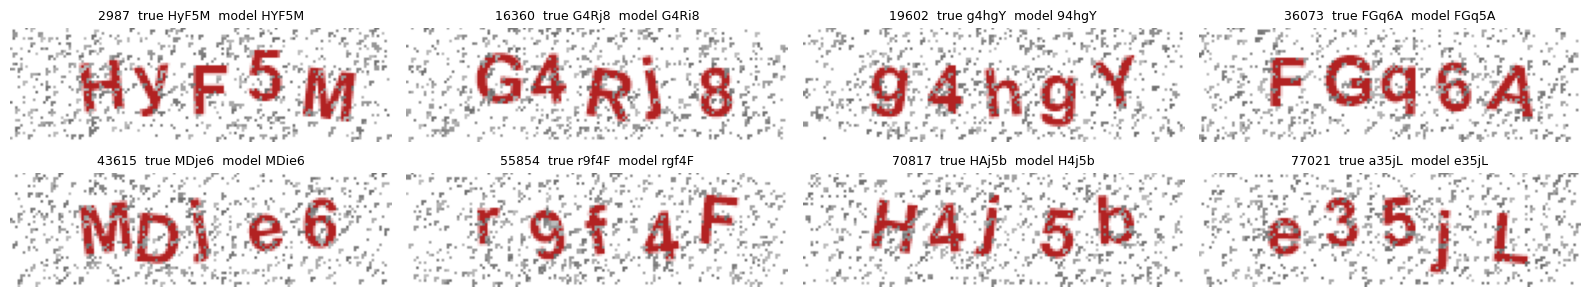

In [12]:
for split in ("val", "test", "gold"):
    r = evaluate(model, split)
    print(f"{split:<5} ({len(data[split][0]):>6} images)  exact {r['exact']:.2%}  char {r['char']:.2%}")

n_checked = sum(bool(g["checked"]) for g in GOLD.values())
if n_checked < len(GOLD):
    print(f"only {n_checked}/{len(GOLD)} gold checked: scores are provisional and flatter the teacher")
teacher, _ = load_model(TEACHER)
for name, m in (("teacher (v1)", teacher), ("v2 baseline", model)):
    print(f"gold, {name}: {evaluate(m, 'gold')['exact']:.2%}")

p_gold, y_gold = predict(model, "gold"), data["gold"][1]
print("per-position accuracy on gold:", [f"{a:.1%}" for a in (p_gold == y_gold).float().mean(0).tolist()])
mix = Counter((ALPHABET[t], ALPHABET[q]) for pp, yy in zip(p_gold, y_gold)
              for t, q in zip(yy.tolist(), pp.tolist()) if t != q)
print("confusions on gold (true -> predicted):", mix.most_common(10))

gold_rows = split_rows["gold"]
wrong = [k for k in range(len(gold_rows)) if not torch.equal(p_gold[k], y_gold[k])]
cols, rows_n = 4, max(1, math.ceil(len(wrong) / 4))
fig, ax = plt.subplots(rows_n, cols, figsize=(16, 1.6 * rows_n), squeeze=False)
for a in ax.flat:
    a.axis("off")
for a, k in zip(ax.flat, wrong):
    a.imshow(prep.open_captcha(gold_rows[k]["id"]).convert("RGB"))
    a.set_title(f"{gold_rows[k]['id']}  true {gold_rows[k]['label']}  model {decode_pred(p_gold[k].tolist())}", fontsize=9)
plt.tight_layout()
plt.show()

## 11. Save, reload, check the reload predicts the same

In [13]:
torch.save({
    "state_dict": model.state_dict(),
    "alphabet": ALPHABET,
    "length": LENGTH,
    "image_size": (H, W),
    "widths": (32, 64, 128, 192),
    "preprocess": "prep.ink: red mask (r - g > 60 and r - b > 60) -> letters 0, rest 255",
    "config": CFG,
    "trained_on": LABELS_CSV,
    "input": "grayscale HxW, x = 1 - pixel/255 (ink = 1), shape (B, 1, H, W)",
    "scores": {s: evaluate(model, s) for s in ("val", "test", "gold")},
}, MODEL_PATH)

reloaded, ckpt = load_model(MODEL_PATH)
assert torch.equal(predict(reloaded, "gold"), predict(model, "gold")), "reloaded model predicts differently"
print(f"saved {MODEL_PATH} ({os.path.getsize(MODEL_PATH) / 1e6:.1f} MB), reload OK:", ckpt["scores"])

saved ../models/captcha_cnn_v2.pt (7.3 MB), reload OK: {'val': {'exact': 0.9863862991333008, 'char': 0.9972772598266602}, 'test': {'exact': 0.9857801795005798, 'char': 0.997156023979187}, 'gold': {'exact': 0.9599999785423279, 'char': 0.9919999837875366}}


## 12. Review 50 at a time: disagreements with Vision first, then the least confident reads
Enter = right, type the truth if wrong, s = skip, q = quit. Settings (N_REVIEW, FOCUS, POOL) at the top of
`../scripts/review.py`. Reviews go to `../data/reviews.json`. After each batch, run 13 (and 14) to fine-tune.

reviewing 50 of the 2000 most doubtful reads of captcha_cnn_v2_ft.pt (2000 of them disagree with Vision); 50 reviewed so far


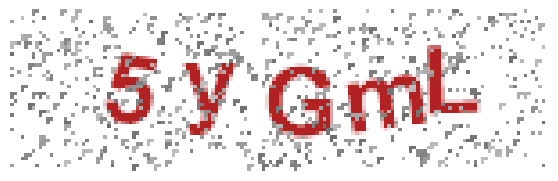

[1/50] 2036  model: 5YGmL  (Vision: -, conf 0.59)  Enter=right / type truth / s=skip / q=quit:  


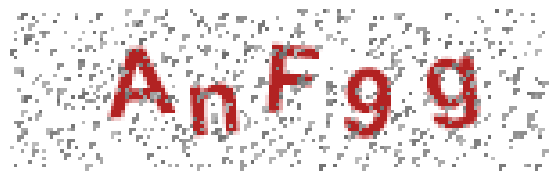

[2/50] 73240  model: AnF9g  (Vision: AnFgg, conf 0.63)  Enter=right / type truth / s=skip / q=quit:  


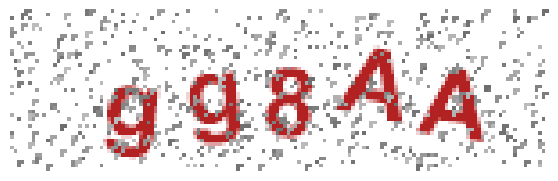

[3/50] 59885  model: gg8AA  (Vision: 998AA, conf 0.61)  Enter=right / type truth / s=skip / q=quit:  


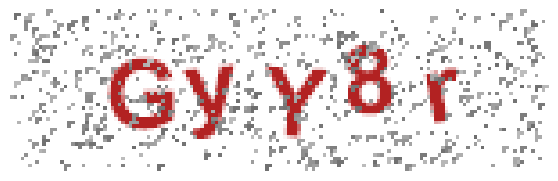

[4/50] 90201  model: GYY8r  (Vision: GyY8r, conf 0.40)  Enter=right / type truth / s=skip / q=quit:  GyY8r


  model wrong: y -> Y @1


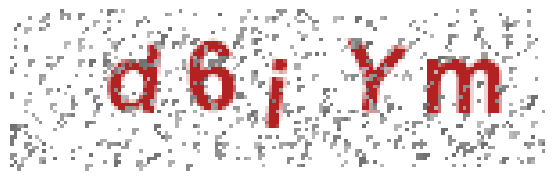

[5/50] 23569  model: d6iYm  (Vision: d6jYm, conf 0.61)  Enter=right / type truth / s=skip / q=quit:  


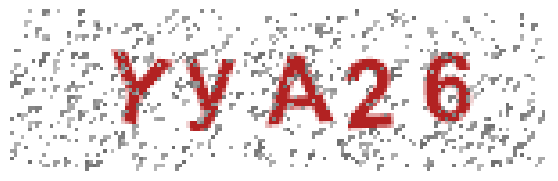

[6/50] 51553  model: YyA26  (Vision: YYA26, conf 0.63)  Enter=right / type truth / s=skip / q=quit:  


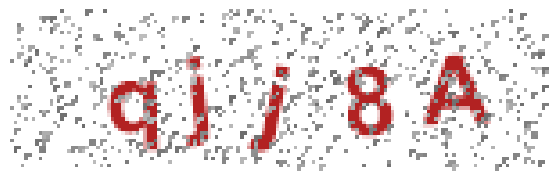

[7/50] 72030  model: qij8A  (Vision: qjj8A, conf 0.54)  Enter=right / type truth / s=skip / q=quit:  qjj8A


  model wrong: j -> i @1


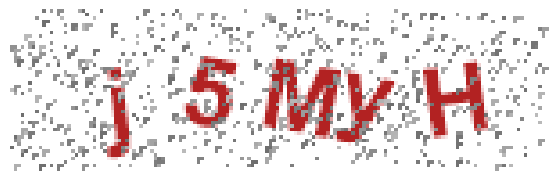

[8/50] 33551  model: j5MyH  (Vision: i5MyH, conf 0.64)  Enter=right / type truth / s=skip / q=quit:  


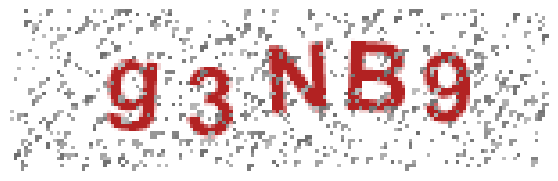

[9/50] 91219  model: 93NB9  (Vision: g3NB9, conf 0.59)  Enter=right / type truth / s=skip / q=quit:  g3NB9


  model wrong: g -> 9 @0


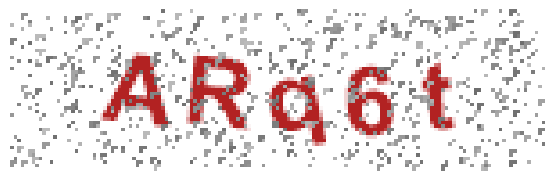

[10/50] 72347  model: ARq6t  (Vision: -, conf 0.39)  Enter=right / type truth / s=skip / q=quit:  


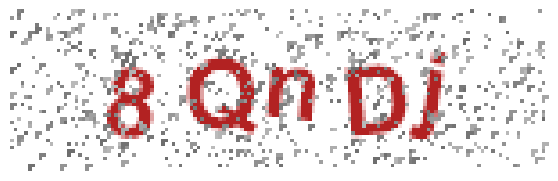

[11/50] 94499  model: 8QnDj  (Vision: 8QnDi, conf 0.53)  Enter=right / type truth / s=skip / q=quit:  


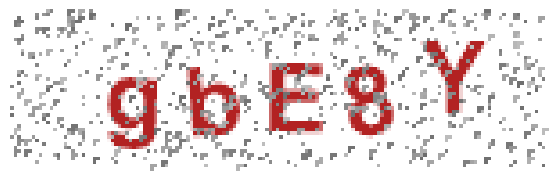

[12/50] 23834  model: gbE8Y  (Vision: gbEgY, conf 0.53)  Enter=right / type truth / s=skip / q=quit:  


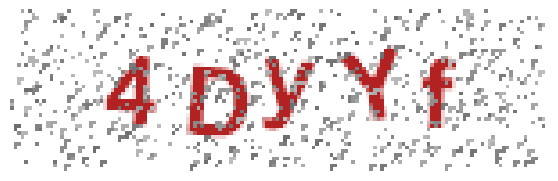

[13/50] 18844  model: 4DyYf  (Vision: 4DYYf, conf 0.59)  Enter=right / type truth / s=skip / q=quit:  


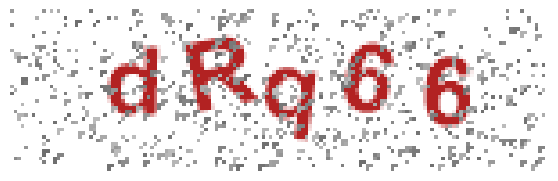

[14/50] 8213  model: dRq66  (Vision: dRg66, conf 0.37)  Enter=right / type truth / s=skip / q=quit:  


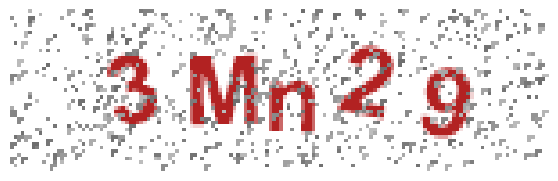

[15/50] 68327  model: 3Mn29  (Vision: 3Mn2g, conf 0.49)  Enter=right / type truth / s=skip / q=quit:  


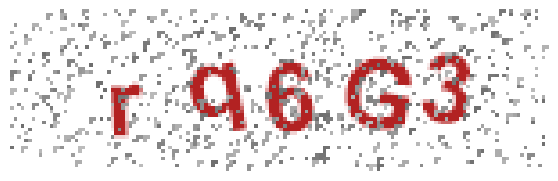

[16/50] 76275  model: rq6G3  (Vision: r96G3, conf 0.64)  Enter=right / type truth / s=skip / q=quit:  


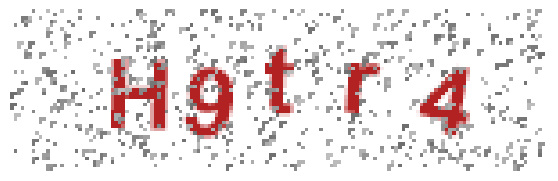

[17/50] 58013  model: H9tr4  (Vision: Hgtr4, conf 0.47)  Enter=right / type truth / s=skip / q=quit:  


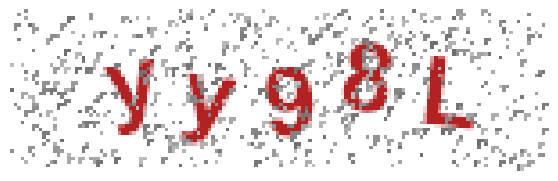

[18/50] 72566  model: yy98L  (Vision: -, conf 0.54)  Enter=right / type truth / s=skip / q=quit:  


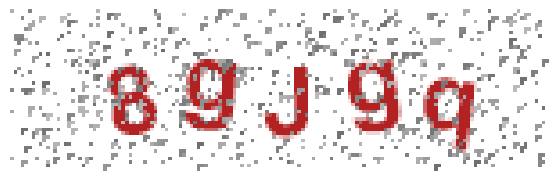

[19/50] 57898  model: 8gJgq  (Vision: -, conf 0.59)  Enter=right / type truth / s=skip / q=quit:  


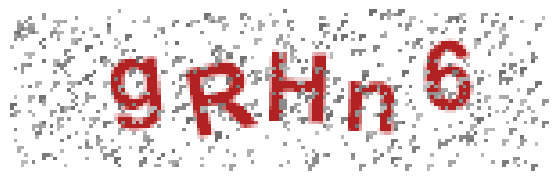

[20/50] 55337  model: gRHn6  (Vision: 9RHn6, conf 0.51)  Enter=right / type truth / s=skip / q=quit:  


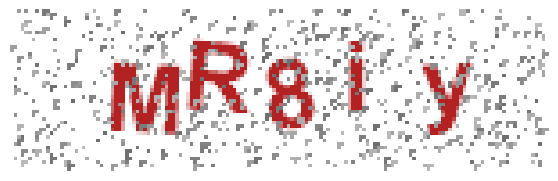

[21/50] 2964  model: MR8iy  (Vision: -, conf 0.48)  Enter=right / type truth / s=skip / q=quit:  


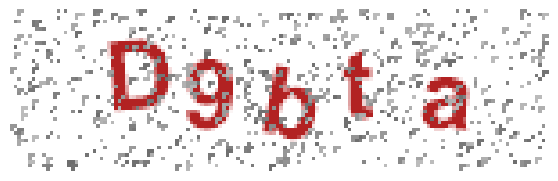

[22/50] 22037  model: D9bta  (Vision: Dgbta, conf 0.50)  Enter=right / type truth / s=skip / q=quit:  


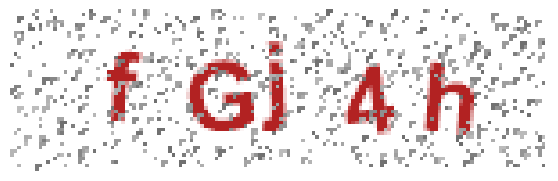

[23/50] 64552  model: fGj4h  (Vision: fGi4h, conf 0.37)  Enter=right / type truth / s=skip / q=quit:  


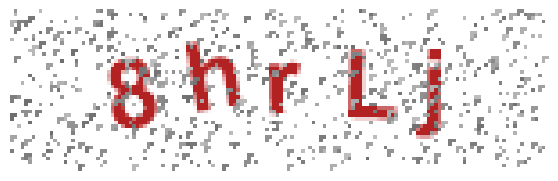

[24/50] 16130  model: 5hrLj  (Vision: -, conf 0.41)  Enter=right / type truth / s=skip / q=quit:  8hrLj


  model wrong: 8 -> 5 @0


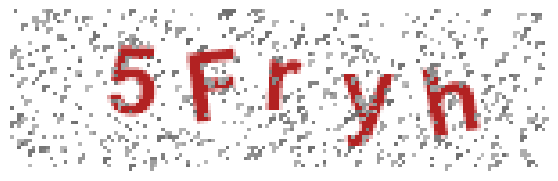

[25/50] 63956  model: 5Fryh  (Vision: 5Fryn, conf 0.48)  Enter=right / type truth / s=skip / q=quit:  


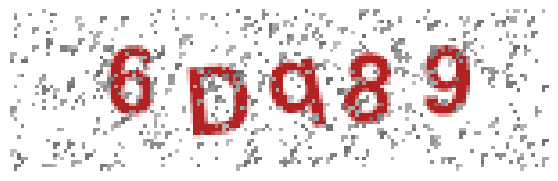

[26/50] 70036  model: 6D989  (Vision: -, conf 0.45)  Enter=right / type truth / s=skip / q=quit:  6Dq89


  model wrong: q -> 9 @2


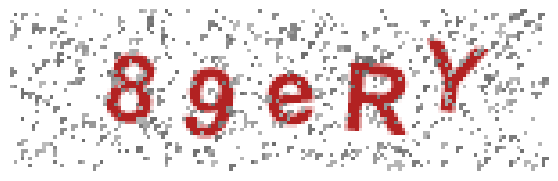

[27/50] 29615  model: 89eRY  (Vision: 8geRY, conf 0.50)  Enter=right / type truth / s=skip / q=quit:  


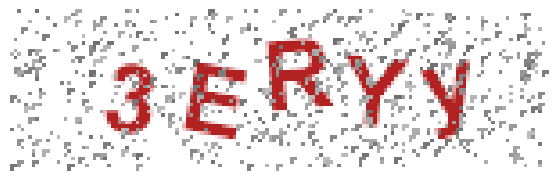

[28/50] 14522  model: 3ERYY  (Vision: JERYY, conf 0.51)  Enter=right / type truth / s=skip / q=quit:  3ERYy


  model wrong: y -> Y @4


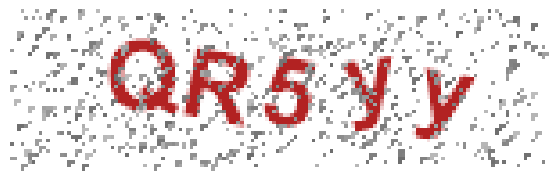

[29/50] 15925  model: QR5yy  (Vision: QR5YY, conf 0.60)  Enter=right / type truth / s=skip / q=quit:  


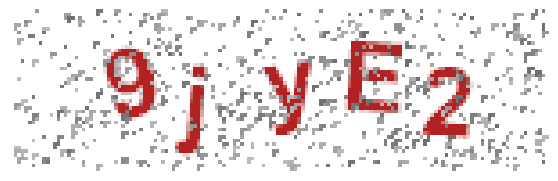

[30/50] 12581  model: 9jyE2  (Vision: 9jYE2, conf 0.46)  Enter=right / type truth / s=skip / q=quit:  


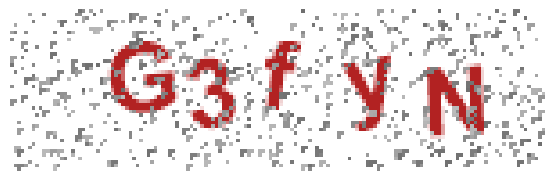

[31/50] 66852  model: G3fyN  (Vision: G3fYN, conf 0.49)  Enter=right / type truth / s=skip / q=quit:  


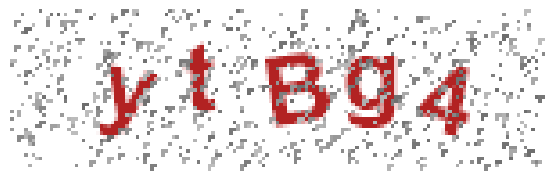

[32/50] 14788  model: ytBg4  (Vision: ytB94, conf 0.59)  Enter=right / type truth / s=skip / q=quit:  


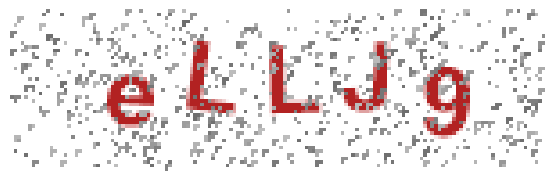

[33/50] 75215  model: eLLJ9  (Vision: eLLJg, conf 0.57)  Enter=right / type truth / s=skip / q=quit:  


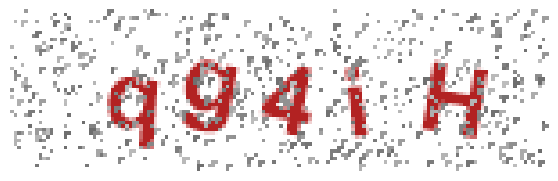

[34/50] 3036  model: q94iH  (Vision: 994fH, conf 0.57)  Enter=right / type truth / s=skip / q=quit:  qg4iH


  model wrong: g -> 9 @1


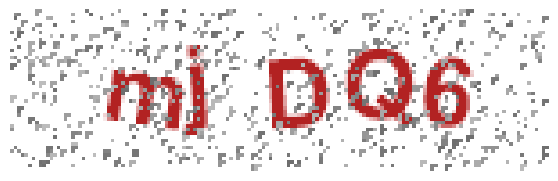

[35/50] 45942  model: miDQ6  (Vision: mjDQ6, conf 0.44)  Enter=right / type truth / s=skip / q=quit:  mjDQ6


  model wrong: j -> i @1


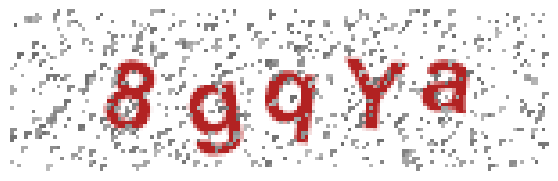

[36/50] 34744  model: 8gqYa  (Vision: 8gqya, conf 0.63)  Enter=right / type truth / s=skip / q=quit:  


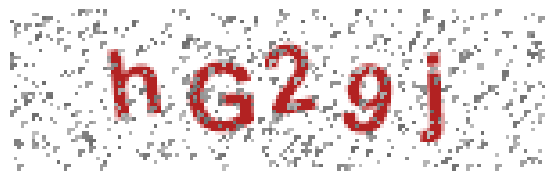

[37/50] 97910  model: hG29j  (Vision: hG2gj, conf 0.51)  Enter=right / type truth / s=skip / q=quit:  


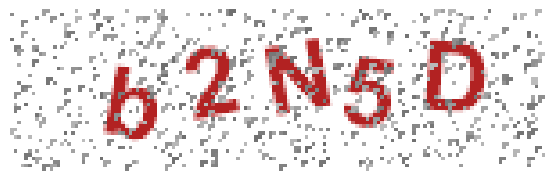

[38/50] 55979  model: b2N5D  (Vision: 62N5D, conf 0.61)  Enter=right / type truth / s=skip / q=quit:  


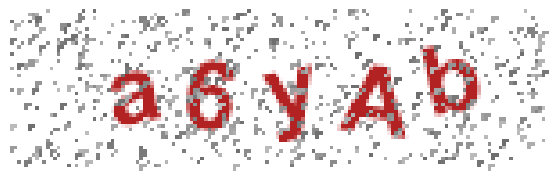

[39/50] 99365  model: a6yAb  (Vision: -, conf 0.41)  Enter=right / type truth / s=skip / q=quit:  


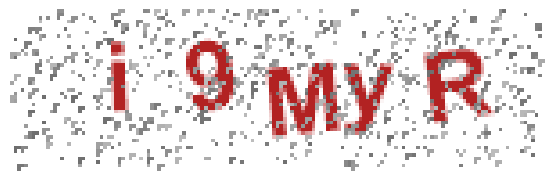

[40/50] 77286  model: i9MyR  (Vision: i9MYR, conf 0.43)  Enter=right / type truth / s=skip / q=quit:  


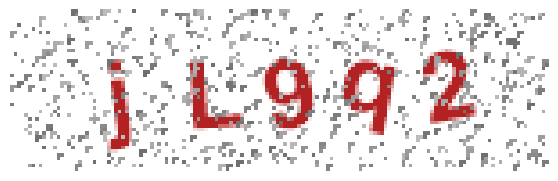

[41/50] 21471  model: jL9q2  (Vision: iL992, conf 0.57)  Enter=right / type truth / s=skip / q=quit:  


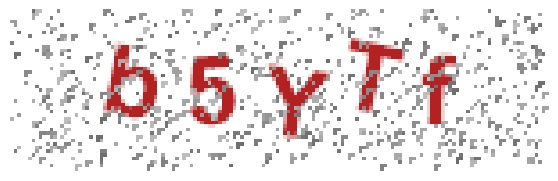

[42/50] 31978  model: b5YTf  (Vision: b5yTf, conf 0.51)  Enter=right / type truth / s=skip / q=quit:  


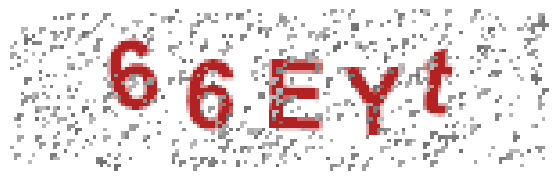

[43/50] 24680  model: 66EYt  (Vision: -, conf 0.51)  Enter=right / type truth / s=skip / q=quit:  


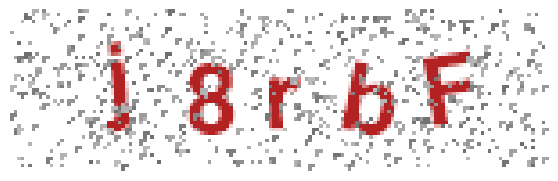

[44/50] 68198  model: j8rbF  (Vision: i8r6F, conf 0.48)  Enter=right / type truth / s=skip / q=quit:  


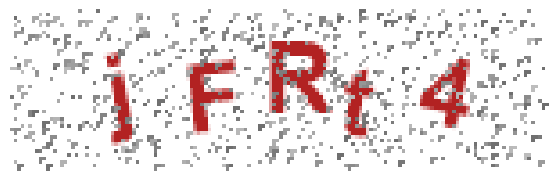

[45/50] 20165  model: jFRf4  (Vision: -, conf 0.49)  Enter=right / type truth / s=skip / q=quit:  


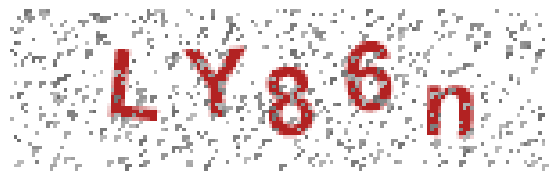

[46/50] 54616  model: LY86n  (Vision: LYgen, conf 0.60)  Enter=right / type truth / s=skip / q=quit:  


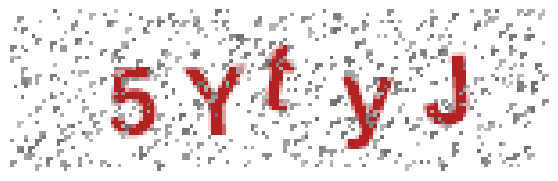

[47/50] 6280  model: 5YtyJ  (Vision: -, conf 0.44)  Enter=right / type truth / s=skip / q=quit:  


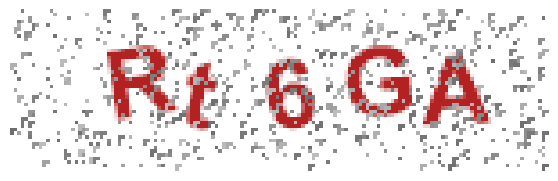

[48/50] 17550  model: Rt6GA  (Vision: Rf6GA, conf 0.51)  Enter=right / type truth / s=skip / q=quit:  


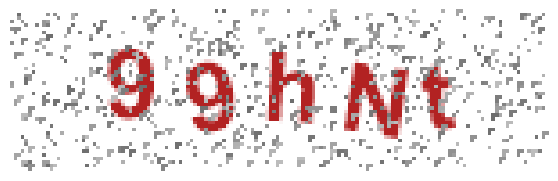

[49/50] 1335  model: 99hNt  (Vision: 9ghNt, conf 0.56)  Enter=right / type truth / s=skip / q=quit:  


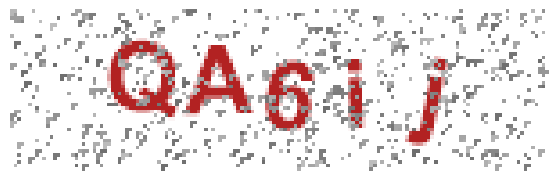

[50/50] 90887  model: QA6ij  (Vision: QA5ij, conf 0.63)  Enter=right / type truth / s=skip / q=quit:  



this run: 50 reviewed, model wrong on 8; 100 reviews in total
this run's confusions (true -> model): [(('y', 'Y'), 2), (('j', 'i'), 2), (('g', '9'), 2), (('8', '5'), 1), (('q', '9'), 1)]


In [17]:
%run -i ../scripts/review.py

## 13. Fine-tune the baseline on all reviews → `../models/captcha_cnn_v2_ft.pt` (re-run after each review batch)

In [18]:
%run -i ../scripts/finetune.py

100 reviews, the reviewing model was wrong on 26
each review repeated 20x per epoch


epoch 1/2  reviewed exact 99.00%  gold exact 98.50%


epoch 2/2  reviewed exact 100.00%  gold exact 98.50%



                  before  ->  after
reviewed  exact  51.00% -> 100.00%   char  90.20% -> 100.00%
gold      exact  96.00% ->  98.50%   char  99.20% ->  99.70%
test      exact  98.58% ->  97.43%   char  99.72% ->  99.48%
saved ../models/captcha_cnn_v2_ft.pt


## 14. What the fine-tune fixed and broke on gold (vs the baseline)

In [19]:
base_model, _ = load_model(MODEL_PATH)
p_base, p_ft, y = predict(base_model, "gold"), predict(ft_model, "gold"), data["gold"][1]
for k, r in enumerate(split_rows["gold"]):
    b, f = torch.equal(p_base[k], y[k]), torch.equal(p_ft[k], y[k])
    if b != f:
        print(f"{'FIXED ' if f else 'BROKEN'} {r['id']}  true {r['label']}  "
              f"baseline {decode_pred(p_base[k].tolist())}  fine-tuned {decode_pred(p_ft[k].tolist())}")

FIXED  2987  true HyF5M  baseline HYF5M  fine-tuned HyF5M
FIXED  16360  true G4Rj8  baseline G4Ri8  fine-tuned G4Rj8
FIXED  19602  true g4hgY  baseline 94hgY  fine-tuned g4hgY
FIXED  36073  true FGq6A  baseline FGq5A  fine-tuned FGq6A
FIXED  43615  true MDje6  baseline MDie6  fine-tuned MDje6
FIXED  55854  true r9f4F  baseline rgf4F  fine-tuned r9f4F
BROKEN 84043  true YgQiJ  baseline YgQiJ  fine-tuned Y9QiJ
